# Assignment 3: Hyperparameter Tuning

**Course:** AAI 6640 — Applied Deep Learning
**Module:** Week 7 (7.7)
**Author:** Muhammad Obaidullah
**Dataset:** CIFAR-10 (Keras)
**Task:** 10-class image classification with fully connected networks (no convolutional layers)

## Overview

**Objective:** tune a fully connected classifier for CIFAR-10 through a sequence of controlled experiments (batch size, then batch normalization, then a five-hyperparameter search run twice, once with random search and once with Bayesian optimization) and select a final model from validation evidence alone.

**Approach:** prepare → baseline → batch size → batch normalization → random search → Bayesian optimization → select → evaluate once on test → compare → reflect.

**Conventions**

- One seed (`SEED = 42`) fixes the train/validation split, every model's initial weights, the mini-batch shuffling order, and the random-search sample. Each run resets the seed before building its model, so two runs differ only in the settings the experiment changes.
- Every run trains for the same fixed **30 epochs** on the same 45,000 training images and is scored every epoch on the same 5,000 validation images. There is no early stopping, so every configuration gets the same budget in epochs.
- **Best validation accuracy** is the maximum over the 30 epochs; **best epoch** is the (1-indexed) epoch where it occurs. Best validation loss is reported separately, with its own epoch.
- The 10,000 test images are used **once**, in Step 7, after the final model is fixed.

**Experimental control**

| Step | What changes | What is held fixed |
|---|---|---|
| 2 Baseline | nothing (reference) | 512-256-128 ReLU, Adam (lr 0.001), batch 128, 30 epochs, split, seed |
| 3 Batch size | batch size: 32, 128, 512 | everything else from Step 2 |
| 4 Batch norm | Dense → **BN** → ReLU in every hidden layer | everything else, including the Step 3 batch size and Adam's default learning rate |
| 5 Random search | learning rate, batch size, depth, width, dropout | BN on, 30 epochs, split, seed, metrics, 8-trial budget |
| 6 Bayesian optimization | same five hyperparameters, same values | same as Step 5; only the method that proposes configurations differs |
| 7 Final model | chosen from Steps 2–6 on validation accuracy | test set untouched until the choice is made |

**Runtime:** up to 20 training runs of 30 epochs each (1 baseline, 2 more batch sizes, 1 BN model, 8 + 8 search trials; a configuration that TPE proposes twice is not retrained) plus one final retraining. On an Apple M1 Pro CPU (no GPU) the whole notebook ran in about 25 minutes; a GPU runtime is faster.

## Setup

Optuna runs the Bayesian optimization in Step 6; the next cell installs it only if it is missing (for example on a fresh Colab runtime). Everything else ships with TensorFlow.

In [1]:
import importlib.util

if importlib.util.find_spec("optuna") is None:
    %pip install --quiet optuna

All imports, constants, and display settings. `enable_op_determinism()` makes TensorFlow choose deterministic kernels, so rerunning the notebook on the same hardware and library versions reproduces every number.

In [2]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # before TensorFlow loads; hides C++ notices

import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # raised when Optuna imports tqdm without ipywidgets

import itertools
import math
import time
from dataclasses import dataclass, replace

import keras
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
import tensorflow as tf
from keras import layers
from keras.datasets import cifar10
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

SEED = 42
EPOCHS = 30
VAL_SIZE = 5_000
BASELINE_BATCH_SIZE = 128
BATCH_SIZES = (32, 128, 512)
N_TRIALS = 8  # trial budget for each search method
N_STARTUP_TRIALS = 3  # random trials before the Bayesian sampler starts modelling (Step 6)
CONVERGENCE_TARGET = 0.45  # validation accuracy used to compare convergence speed
CLASS_NAMES = (
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
)

tf.config.experimental.enable_op_determinism()
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

set_matplotlib_formats("retina")
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "font.size": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.3,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 4)

print(
    f"TensorFlow {tf.__version__} | Keras {keras.__version__} | "
    f"scikit-learn {sklearn.__version__} | Optuna {optuna.__version__} | "
    f"NumPy {np.__version__} | pandas {pd.__version__}"
)
gpus = tf.config.list_physical_devices("GPU")
print(f"Accelerator: {', '.join(gpu.name for gpu in gpus) if gpus else 'none (CPU only)'}")

TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1 | Optuna 5.0.0 | NumPy 2.5.3 | pandas 3.0.6
Accelerator: none (CPU only)


## Step 1 — Prepare the data

CIFAR-10 ships as 50,000 training and 10,000 test images, each 32 × 32 pixels with three 8-bit colour channels (integers 0–255), labelled with one of ten classes.

Preparation:

1. **Flatten** each image to a 3,072-value vector (32 × 32 × 3), the input a dense network expects.
2. **Normalize** pixels to [0, 1] by dividing by 255.
3. **Split** the 50,000 training images into 45,000 training and 5,000 validation images with a seeded, shuffled, **stratified** split, so both keep the 10 % per-class share of the original. The original 10,000 test images stay as the test set.
4. **Keep labels as integers** 0–9, flattened from shape (n, 1) to (n,), for `sparse_categorical_crossentropy`.

In [3]:
(X_train_full, y_train_full), (X_test_raw, y_test_raw) = cifar10.load_data()

print(f"Training images: {X_train_full.shape} {X_train_full.dtype}, labels {y_train_full.shape}")
print(f"Test images:     {X_test_raw.shape} {X_test_raw.dtype}, labels {y_test_raw.shape}")
print(f"Pixel range: {X_train_full.min()} to {X_train_full.max()}")

Training images: (50000, 32, 32, 3) uint8, labels (50000, 1)
Test images:     (10000, 32, 32, 3) uint8, labels (10000, 1)
Pixel range: 0 to 255


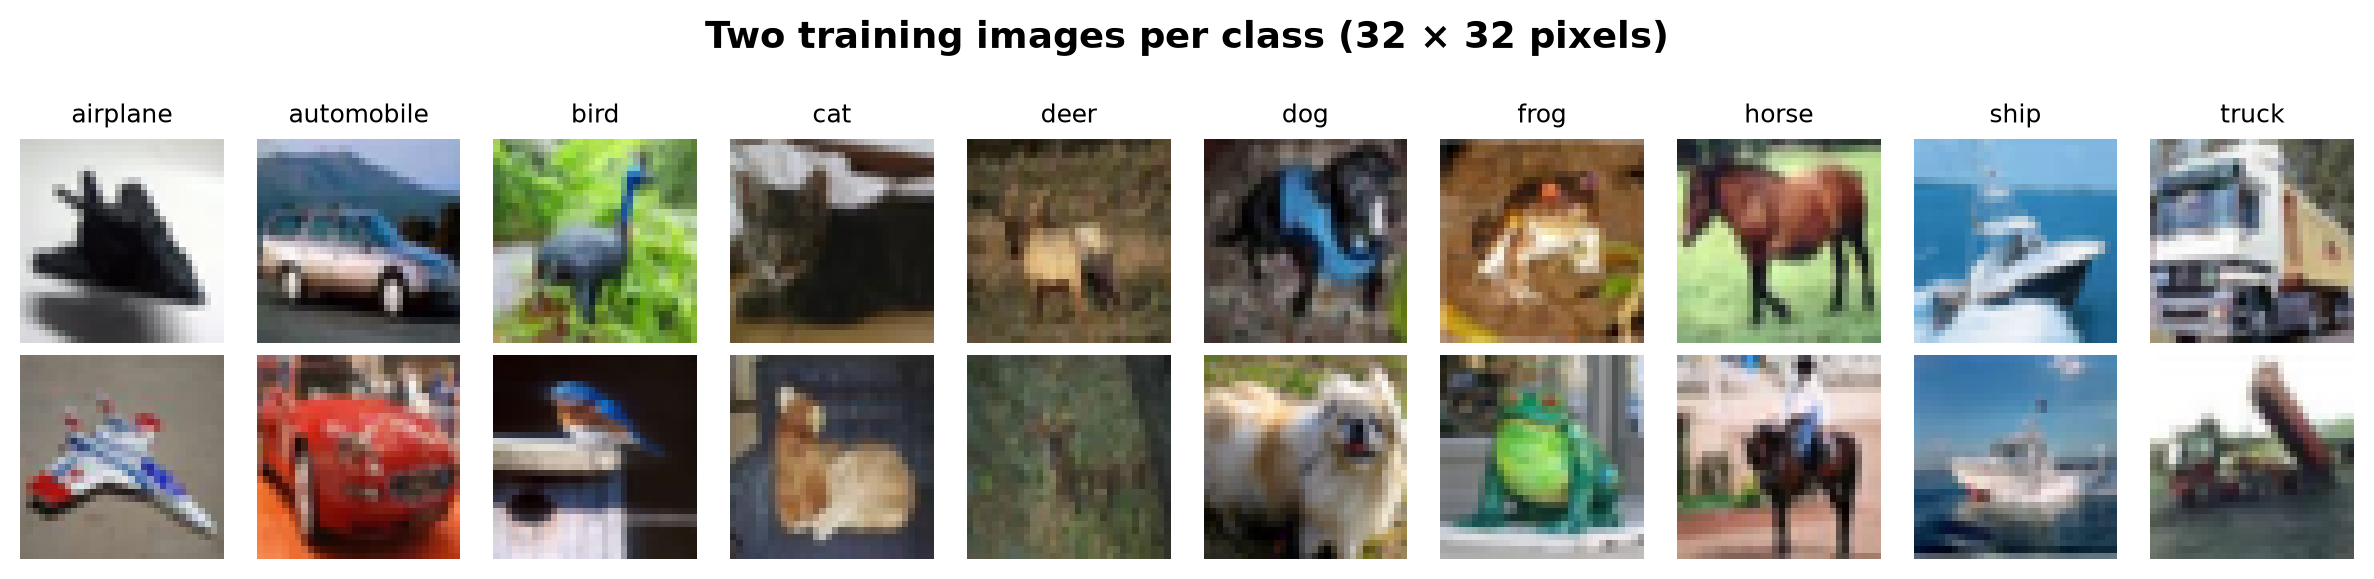

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for label, column in zip(range(10), axes.T):
    examples = np.flatnonzero(y_train_full.ravel() == label)[:2]
    for ax, index in zip(column, examples):
        ax.imshow(X_train_full[index])
        ax.axis("off")
    column[0].set_title(CLASS_NAMES[label], fontsize=9, fontweight="normal")
fig.suptitle("Two training images per class (32 × 32 pixels)", fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
@dataclass(frozen=True)
class Split:
    '''One partition: flattened pixels `X` (rows × 3,072, float32 in [0, 1]) and integer labels `y` (rows,).'''

    X: np.ndarray
    y: np.ndarray


@dataclass(frozen=True)
class Splits:
    '''The training, validation, and test partitions.'''

    train: Split
    val: Split
    test: Split


def flatten_and_scale(images: np.ndarray) -> np.ndarray:
    '''Flatten n × 32 × 32 × 3 uint8 images to n × 3,072 float32 values in [0, 1].'''
    return images.reshape(len(images), -1).astype(np.float32) / 255.0


def split_indices(labels: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    '''Seeded, shuffled, stratified split of row indices into training and validation.'''
    return train_test_split(
        np.arange(len(labels)),
        test_size=VAL_SIZE,
        shuffle=True,
        stratify=labels,
        random_state=SEED,
    )


def prepare() -> Splits:
    '''45,000 / 5,000 stratified training/validation split plus the original test set.'''
    labels = y_train_full.ravel().astype(np.int64)
    train_idx, val_idx = split_indices(labels)
    pixels = flatten_and_scale(X_train_full)
    return Splits(
        Split(pixels[train_idx], labels[train_idx]),
        Split(pixels[val_idx], labels[val_idx]),
        Split(flatten_and_scale(X_test_raw), y_test_raw.ravel().astype(np.int64)),
    )


data = prepare()
N_TRAIN, N_FEATURES = data.train.X.shape

### Checking the split

Sizes, shapes, pixel ranges, the per-class counts in each split, and whether repeating the split reproduces the same rows.

In [6]:
parts = {"Training": data.train, "Validation": data.val, "Test": data.test}
pd.DataFrame(
    {
        name: {
            "Rows": len(part.y),
            "Features": part.X.shape[1],
            "Pixel min": part.X.min(),
            "Pixel max": part.X.max(),
            "Pixel mean": part.X.mean(),
            "Label dtype": str(part.y.dtype),
        }
        for name, part in parts.items()
    }
).T

,Rows,Features,Pixel min,Pixel max,Pixel mean,Label dtype
Training,45000,3072,0.0,1.0,0.4732,int64
Validation,5000,3072,0.0,1.0,0.4745,int64
Test,10000,3072,0.0,1.0,0.4766,int64


In [7]:
class_counts = pd.DataFrame(
    {name: np.bincount(part.y, minlength=10) for name, part in parts.items()},
    index=pd.Index(CLASS_NAMES, name="Class"),
)
class_shares = class_counts / class_counts.sum()
print("Class share range per split (%):")
print((100 * class_shares.agg(["min", "max"])).round(2).to_string())

first_train, first_val = split_indices(y_train_full.ravel())
second_train, second_val = split_indices(y_train_full.ravel())
print(
    "\nRepeating the split reproduces the same rows:",
    np.array_equal(first_train, second_train) and np.array_equal(first_val, second_val),
)
class_counts

Class share range per split (%):
     Training  Validation  Test
min      10.0        10.0  10.0
max      10.0        10.0  10.0

Repeating the split reproduces the same rows: True


,Training,Validation,Test
Class,,,
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000


**Why normalization is required.** Raw pixels are integers from 0 to 255. Keras's default Glorot-uniform initializer sizes the first layer's weights for inputs of roughly unit scale; feeding values up to 255 makes the first layer's pre-activations about 255 times larger than intended, so early activations and gradients are large and uneven and Adam's first updates are erratic. Dividing by 255 maps every input to [0, 1] with the same fixed transform for all three splits. It uses no statistics estimated from the data, so it cannot leak information from the validation or test images, and it preserves the relative intensities that carry the image content.

**Why a separate validation set is required.** Every decision in this notebook (the batch size, whether to use batch normalization, which search configuration wins, how many epochs to train) is made by comparing scores. If those scores came from the test set, the test set would be part of model selection and its accuracy would be optimistically biased: with enough comparisons, some configuration scores well on those particular 10,000 images by chance. Training accuracy cannot stand in either, because it rewards memorization and cannot detect overfitting. The 5,000 validation images are held out from gradient updates and used for every comparison, which leaves the test set as a single, unbiased estimate of performance on new images. Stratifying the split keeps each class at 500 validation images, so validation accuracy is not skewed by an uneven class mix.

## Shared training and reporting helpers

Every experiment goes through the same functions, so the procedure cannot drift between steps:

- `Config` holds every setting that defines a run. Its defaults are the Step 2 baseline; later steps change fields with `replace(...)`, which makes the changed variable explicit.
- `build_model` builds the dense network. Without BN a hidden layer is `Dense(ReLU)`; with BN it is `Dense → BatchNormalization → ReLU`; dropout, when used, follows the activation.
- `train` resets the seed, trains for `config.epochs` epochs, and records per-epoch training and validation loss and accuracy plus wall-clock seconds.
- `summarize` reduces a run to the metrics used in every table; `observe` turns them into the short "key observation" text.

**Diagnostics used in the tables**

| Metric | Definition | What it indicates |
|---|---|---|
| Best val accuracy / best epoch | maximum validation accuracy and the epoch where it occurs | performance used for selection |
| Best val loss / its epoch | minimum validation loss and its epoch | calibration-aware performance; the onset of overfitting |
| Epochs to 45 % | first epoch with validation accuracy ≥ 0.45 | convergence speed on a common target |
| Updates to 45 % | epochs to 45 % × weight updates per epoch | convergence speed in optimizer steps, comparable across batch sizes |
| Val-loss rise | final val loss ÷ minimum val loss − 1 | overfitting after the best epoch |
| Gap at final epoch | training − validation accuracy at epoch 30, in points | generalization gap |
| Val-acc noise | standard deviation of validation accuracy around its centred 5-epoch rolling mean, in points | epoch-to-epoch instability, with the trend removed |
| Train time / median s per epoch | wall-clock seconds, including validation | computational cost; the median ignores the first epoch's graph-compilation overhead |

A run is marked **unstable** if its loss became NaN, its validation loss ends at least 25 % above its minimum, or its val-acc noise is at least 1.5 points.

**Resolution of the validation set.** With 5,000 validation images and accuracy near 50 %, one binomial standard error is √(0.5 × 0.5 / 5,000) ≈ 0.71 percentage points. Differences smaller than about one point between two runs are within sampling noise and should not be over-read. All runs are scored on the same 5,000 images, so a comparison between two runs is paired: the standard error of their difference depends on how often the two models disagree, and it is usually close to this figure. Statements such as "2.7 standard errors" in the text are expressed in units of this 0.71-point yardstick. They are not formal significance tests, and they ignore seed-to-seed variation, which was not measured.

In [8]:
VAL_SE = math.sqrt(0.25 / VAL_SIZE)  # binomial standard error of validation accuracy near 50 %
UNSTABLE_LOSS_RISE = 0.25  # final val loss ≥ 25 % above its minimum → marked as overfitting
LARGE_GAP_PTS = 15.0  # train − val accuracy at the final epoch, in points
NOISY_PTS = 1.5  # val-acc noise at or above this is marked as unstable


@dataclass(frozen=True)
class Config:
    '''Every setting that defines one run. Defaults are the Step 2 baseline.'''

    units: tuple[int, ...] = (512, 256, 128)
    batch_norm: bool = False
    dropout: float = 0.0
    learning_rate: float = 1e-3  # Adam's default, so Adam(1e-3) is identical to optimizer="adam"
    batch_size: int = BASELINE_BATCH_SIZE
    epochs: int = EPOCHS

    @property
    def updates_per_epoch(self) -> int:
        return math.ceil(N_TRAIN / self.batch_size)

    def describe(self) -> str:
        widths = "-".join(map(str, self.units))
        return (
            f"{len(self.units)} × [{widths}], BN {'on' if self.batch_norm else 'off'}, "
            f"dropout {self.dropout:g}, lr {self.learning_rate:g}, batch {self.batch_size}"
        )


def build_model(config: Config) -> keras.Model:
    '''Dense classifier: hidden layers Dense(ReLU), or Dense → BN → ReLU; dropout after the activation.'''
    model = keras.Sequential(name="dense_classifier")
    model.add(keras.Input(shape=(N_FEATURES,)))
    for i, width in enumerate(config.units, start=1):
        if config.batch_norm:
            model.add(layers.Dense(width, name=f"dense_{i}"))
            model.add(layers.BatchNormalization(name=f"batch_norm_{i}"))
            model.add(layers.Activation("relu", name=f"relu_{i}"))
        else:
            model.add(layers.Dense(width, activation="relu", name=f"dense_{i}"))
        if config.dropout > 0:
            model.add(layers.Dropout(config.dropout, name=f"dropout_{i}"))
    model.add(layers.Dense(10, activation="softmax", name="output"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=config.learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


class EpochTimer(keras.callbacks.Callback):
    '''Wall-clock seconds per epoch, including the validation pass.'''

    def on_train_begin(self, logs=None):
        self.seconds = []

    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.seconds.append(time.perf_counter() - self._start)


@dataclass(frozen=True, eq=False)
class Run:
    '''One trained configuration and its per-epoch history (index = epoch, starting at 1).'''

    name: str
    config: Config
    history: pd.DataFrame  # loss, accuracy, val_loss, val_accuracy, seconds

    @property
    def diverged(self) -> bool:
        has_nan = self.history[["loss", "val_loss"]].isna().to_numpy().any()
        return bool(has_nan) or len(self.history) < self.config.epochs

    @property
    def best_val_accuracy(self) -> float:
        return float(self.history["val_accuracy"].max())

    @property
    def best_epoch(self) -> int:
        return int(self.history["val_accuracy"].idxmax())


def train(name: str, config: Config) -> tuple[Run, keras.Model]:
    '''Train `config` from a fresh seed on the training split, scoring the validation split each epoch.'''
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_model(config)
    timer = EpochTimer()
    fit = model.fit(
        data.train.X,
        data.train.y,
        validation_data=(data.val.X, data.val.y),
        epochs=config.epochs,
        batch_size=config.batch_size,
        shuffle=True,
        verbose=0,
        callbacks=[timer, keras.callbacks.TerminateOnNaN()],
    )
    history = pd.DataFrame(fit.history)
    history["seconds"] = timer.seconds[: len(history)]
    history.index = pd.RangeIndex(1, len(history) + 1, name="epoch")
    run = Run(name, config, history)
    print(
        f"{name:<24} best val acc {run.best_val_accuracy:.4f} @ epoch {run.best_epoch:>2} | "
        f"min val loss {history['val_loss'].min():.4f} | {history['seconds'].sum():6.1f} s"
        + ("  [diverged]" if run.diverged else "")
    )
    return run, model

In [9]:
EPOCH_COLUMNS = ("Best epoch", "Best val-loss epoch", "Epochs to 45%", "Updates to 45%", "Updates/epoch")


def epochs_to(history: pd.DataFrame, target: float) -> float:
    '''First epoch whose validation accuracy reaches `target`; NaN if never reached.'''
    reached = history.index[history["val_accuracy"] >= target]
    return float(reached[0]) if len(reached) else float("nan")


def val_noise_pts(history: pd.DataFrame) -> float:
    '''Std of validation accuracy around its centred 5-epoch rolling mean, in points.'''
    trend = history["val_accuracy"].rolling(5, center=True, min_periods=3).mean()
    return float(100 * (history["val_accuracy"] - trend).std())


def summarize(run: Run) -> dict[str, float]:
    '''Every metric reported in the result tables.'''
    h, config = run.history, run.config
    best = run.best_epoch
    to_target = epochs_to(h, CONVERGENCE_TARGET)
    return {
        "Best val accuracy": run.best_val_accuracy,
        "Best epoch": best,
        "Best val loss": h["val_loss"].min(),
        "Best val-loss epoch": int(h["val_loss"].idxmin()),
        "Train acc at best epoch": h.loc[best, "accuracy"],
        "Epochs to 45%": to_target,
        "Updates to 45%": to_target * config.updates_per_epoch,
        "Val-loss rise (%)": 100 * (h["val_loss"].iloc[-1] / h["val_loss"].min() - 1),
        "Gap at final epoch (pts)": 100 * (h["accuracy"].iloc[-1] - h["val_accuracy"].iloc[-1]),
        "Val-acc noise (pts)": val_noise_pts(h),
        "Updates/epoch": config.updates_per_epoch,
        "Train time (s)": h["seconds"].sum(),
        "Median s/epoch": h["seconds"].median(),
    }


def observe(run: Run, reference: float | None = None) -> str:
    '''Short rule-based description of a run's training behaviour, from the metrics above.'''
    s, notes = summarize(run), []
    if run.diverged:
        notes.append(f"diverged (NaN loss) at epoch {len(run.history)}")
    if s["Best epoch"] >= run.config.epochs - 2:
        if s["Best val-loss epoch"] >= run.config.epochs - 2:
            notes.append("still improving at the last epoch")
        else:
            notes.append(
                f"val acc peaks late (epoch {s['Best epoch']}) but val loss bottomed at epoch "
                f"{s['Best val-loss epoch']}"
            )
    if s["Val-loss rise (%)"] >= 100 * UNSTABLE_LOSS_RISE:
        notes.append(
            f"overfits: val loss +{s['Val-loss rise (%)']:.0f}% after epoch {s['Best val-loss epoch']}"
        )
    if s["Gap at final epoch (pts)"] >= LARGE_GAP_PTS:
        notes.append(f"train-val gap {s['Gap at final epoch (pts)']:.0f} pts")
    if s["Val-acc noise (pts)"] >= NOISY_PTS:
        notes.append(f"noisy val accuracy (±{s['Val-acc noise (pts)']:.1f} pts)")
    if not notes:
        notes.append("smooth convergence, small gap")
    if reference is not None:
        notes.append(f"{100 * (s['Best val accuracy'] - reference):+.1f} pts vs baseline")
    return "; ".join(notes)


def is_unstable(run: Run) -> bool:
    '''Diverged, overfitting past the loss-rise threshold, or noisy.'''
    s = summarize(run)
    return (
        run.diverged
        or s["Val-loss rise (%)"] >= 100 * UNSTABLE_LOSS_RISE
        or s["Val-acc noise (pts)"] >= NOISY_PTS
    )


def summary_table(runs: dict, columns: list[str]) -> pd.DataFrame:
    '''Selected summary metrics, one row per run.'''
    table = pd.DataFrame({name: summarize(run) for name, run in runs.items()}).T[columns]
    for column in set(EPOCH_COLUMNS) & set(columns):
        table[column] = table[column].round().astype("Int64")  # nullable: NaN if 45 % never reached
    return table

In [10]:
def plot_curves(runs: dict[str, Run], title: str) -> None:
    '''Training (dashed) and validation (solid) loss and accuracy per epoch, one colour per run.'''
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.5))
    for colour, (label, run) in enumerate(runs.items()):
        h = run.history
        for ax, metric in ((ax_loss, "loss"), (ax_acc, "accuracy")):
            ax.plot(h.index, h[metric], "--", color=f"C{colour}", alpha=0.7)
            ax.plot(h.index, h[f"val_{metric}"], "-", color=f"C{colour}", label=label)
        ax_acc.plot(run.best_epoch, run.best_val_accuracy, "o", color=f"C{colour}")
    ax_loss.set(title="Loss", xlabel="Epoch", ylabel="Sparse categorical cross-entropy")
    ax_acc.set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
    style = [
        plt.Line2D([], [], color="grey", ls="--", label="training"),
        plt.Line2D([], [], color="grey", ls="-", label="validation"),
        plt.Line2D([], [], color="grey", marker="o", ls="", label="best val accuracy"),
    ]
    handles, _ = ax_acc.get_legend_handles_labels()
    ax_acc.legend(handles=handles + style, loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()

## Step 2 — Baseline model

The fixed reference configuration: 3,072 → 512 → 256 → 128 → 10, ReLU hidden layers, softmax output, no dropout, no batch normalization, Adam with its defaults (learning rate 0.001), batch size 128, 30 epochs. Every later result is read against this run.

In [11]:
build_model(Config()).summary()

Model: "dense_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
baseline, _ = train("Baseline", Config())
BASELINE_ACC = baseline.best_val_accuracy

Baseline                 best val acc 0.4870 @ epoch 28 | min val loss 1.4591 |   69.1 s


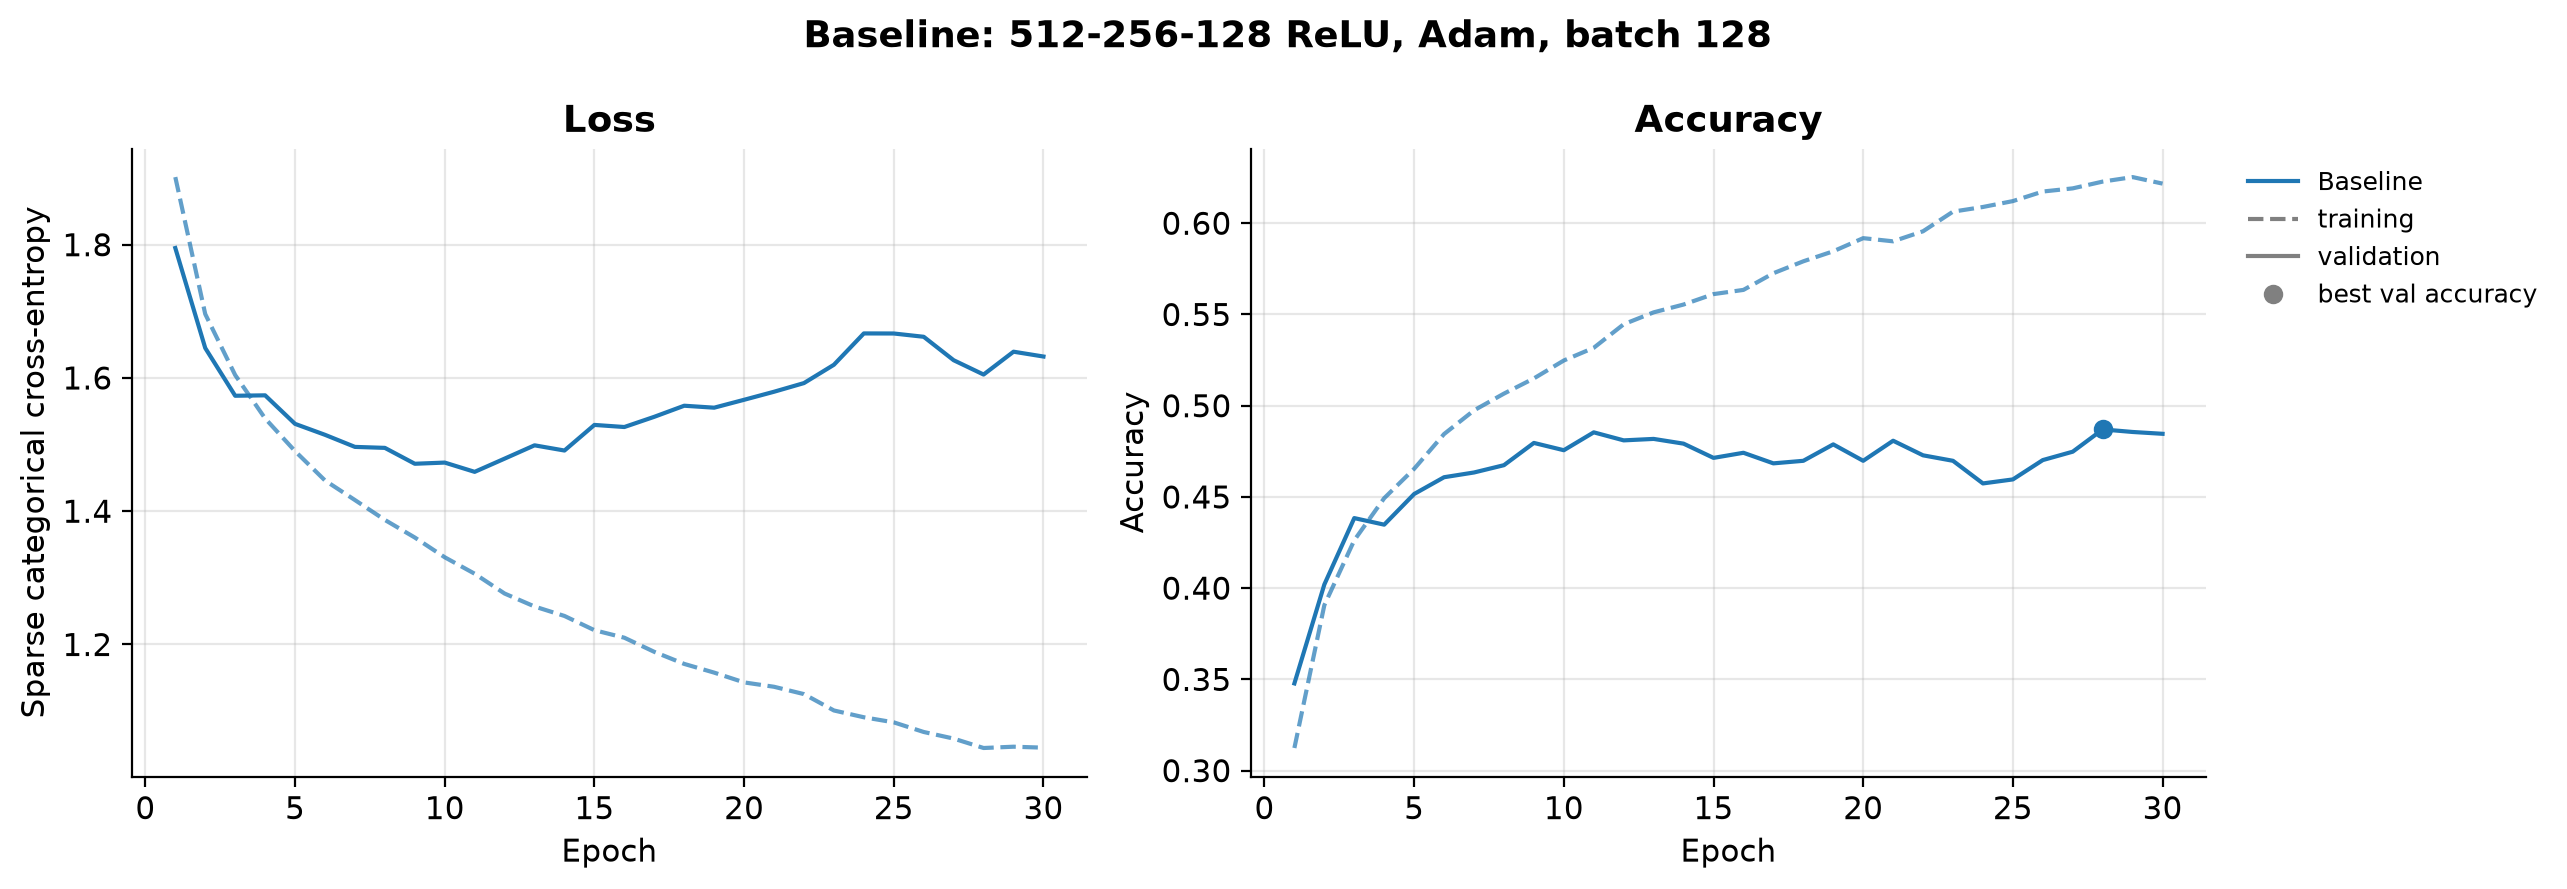

,Best val accuracy,Best epoch,Best val loss,Best val-loss epoch,Train acc at best epoch,Val-loss rise (%),Gap at final epoch (pts),Val-acc noise (pts),Train time (s)
Baseline,0.487,28,1.4591,11,0.6228,11.8625,13.7111,1.0661,69.1379


In [13]:
plot_curves({"Baseline": baseline}, "Baseline: 512-256-128 ReLU, Adam, batch 128")
summary_table(
    {"Baseline": baseline},
    [
        "Best val accuracy", "Best epoch", "Best val loss", "Best val-loss epoch",
        "Train acc at best epoch", "Val-loss rise (%)", "Gap at final epoch (pts)",
        "Val-acc noise (pts)", "Train time (s)",
    ],
)

**Baseline training behaviour.**

**Convergence.** Training loss falls steadily, from 1.90 after epoch 1 to about 1.05 by epoch 28, where it levels off (1.044–1.047 over epochs 28–30). Validation loss drops quickly for three epochs (1.80 → 1.57), reaches its minimum of **1.459 at epoch 11**, and then climbs back to 1.632 by epoch 30 (+11.9 %). Validation accuracy passes 45 % at epoch 5 and is 47.6 % by epoch 10. After that it moves sideways in a 45.7–48.7 % band. The recorded best, **48.70 % at epoch 28**, is only about 1.1 points (≈ 1.6 standard errors) above the epoch-10 value, so nearly everything this network learns that transfers to new images is learnt in the first ten epochs.

**Stability.** The run is stable. Val-acc noise is 1.07 points, below the 1.5-point threshold, and neither loss curve shows spikes or divergence.

**Underfitting vs. overfitting.** Up to about epoch 5 the model underfits: training and validation accuracy are almost equal (46.5 % vs. 45.2 % at epoch 5) and both are still rising. From the validation-loss minimum at epoch 11 onward it overfits: training loss keeps falling (1.30 → 1.05) and training accuracy keeps rising (53 % → 62 %) while validation loss rises. Validation accuracy does not collapse, because cross-entropy also penalises growing over-confidence on images the model already gets wrong, and that happens before the arg-max predictions change. Validation loss is therefore the earlier overfitting signal, and its minimum (epoch 11) and the accuracy maximum (epoch 28) disagree on the best epoch.

**Train–validation gap.** 13.6 points at the best epoch (62.3 % vs. 48.7 %) and 13.7 points at epoch 30. With 1.74 million parameters, about 39 per training image, and no dropout or weight decay, the network has the capacity to memorise image-specific pixel patterns, and the widening gap shows it doing so.

**Why the network plateaus near 49 %.** Flattening turns each image into 3,072 independent numbers. Every first-layer unit has a separate weight for each pixel position and colour channel, so a feature learnt at one position (an ear, a wheel) does not transfer to the same feature a few pixels away. With no weight sharing and no translation invariance, the network can use colour distributions and coarse global layout but cannot build position-independent shape features. That is why it reaches about five times chance (10 %) and then stalls.

## Step 3 — Compare batch sizes

Only the batch size changes: 32, 128, 512. Architecture, optimizer, learning rate, epochs, split, and seed are the Step 2 values.

The batch-128 run is the Step 2 baseline itself: its configuration is identical, and with a fixed seed and deterministic kernels a rerun would reproduce it exactly (Step 7 verifies this reproducibility on the final model), so it is reused rather than retrained.

**Updates per epoch differ.** An epoch is one pass over the 45,000 training images, so it contains ⌈45,000 / batch size⌉ weight updates: 1,407 at batch 32, 352 at batch 128, and 88 at batch 512. After the same number of epochs, the batch-32 model has taken 16 times as many optimizer steps as the batch-512 model, each from a noisier gradient estimate. Comparisons at equal epochs therefore mix two effects (gradient noise and number of steps), so validation loss is also plotted against cumulative weight updates.

In [14]:
batch_runs = {BASELINE_BATCH_SIZE: baseline}
for batch_size in BATCH_SIZES:
    if batch_size not in batch_runs:
        batch_runs[batch_size], _ = train(
            f"Batch {batch_size}", replace(Config(), batch_size=batch_size)
        )
batch_runs = dict(sorted(batch_runs.items()))

Batch 32                 best val acc 0.4650 @ epoch 24 | min val loss 1.5272 |  226.0 s


Batch 512                best val acc 0.5062 @ epoch 21 | min val loss 1.4273 |   30.3 s


In [15]:
batch_table = summary_table(
    batch_runs,
    [
        "Best val accuracy", "Best val loss", "Best epoch", "Train time (s)",
        "Median s/epoch", "Updates/epoch", "Epochs to 45%", "Updates to 45%",
        "Val-loss rise (%)", "Val-acc noise (pts)",
    ],
)
batch_table.index.name = "Batch size"
batch_table

,Best val accuracy,Best val loss,Best epoch,Train time (s),Median s/epoch,Updates/epoch,Epochs to 45%,Updates to 45%,Val-loss rise (%),Val-acc noise (pts)
Batch size,,,,,,,,,,
32,0.4650,1.5272,24,226.0278,7.4422,1407,8,11256,17.6096,0.7399
128,0.4870,1.4591,28,69.1379,2.2517,352,5,1760,11.8625,1.0661
512,0.5062,1.4273,21,30.3204,0.9735,88,9,792,4.2380,0.9202


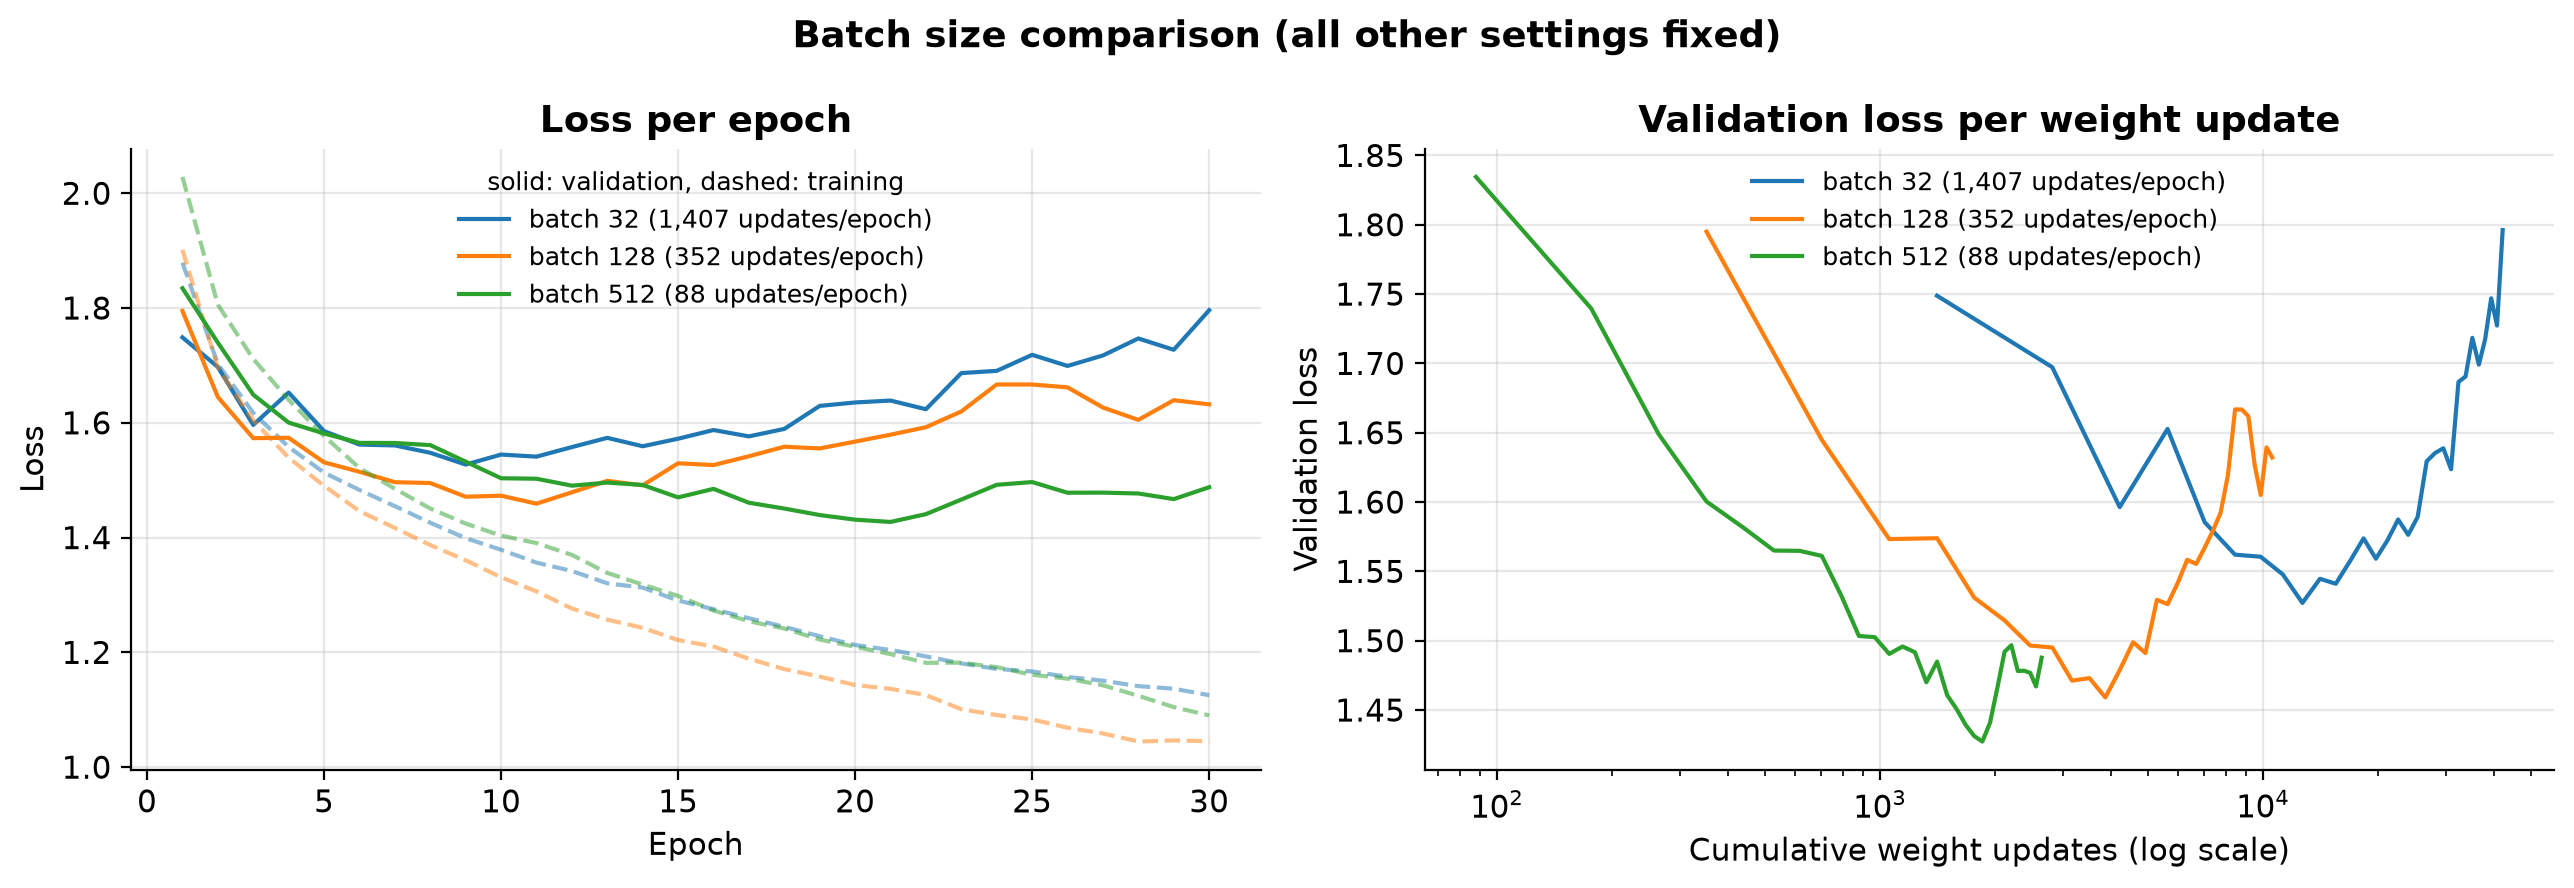

In [16]:
fig, (ax_epoch, ax_steps) = plt.subplots(1, 2, figsize=(13, 4.5))
for colour, (batch_size, run) in enumerate(batch_runs.items()):
    h = run.history
    updates = h.index * run.config.updates_per_epoch
    label = f"batch {batch_size} ({run.config.updates_per_epoch:,} updates/epoch)"
    ax_epoch.plot(h.index, h["val_loss"], color=f"C{colour}", label=label)
    ax_epoch.plot(h.index, h["loss"], "--", color=f"C{colour}", alpha=0.5)
    ax_steps.plot(updates, h["val_loss"], color=f"C{colour}", label=label)
ax_epoch.set(title="Loss per epoch", xlabel="Epoch", ylabel="Loss")
ax_steps.set(
    title="Validation loss per weight update",
    xlabel="Cumulative weight updates (log scale)",
    ylabel="Validation loss",
    xscale="log",
)
ax_epoch.legend(fontsize=9, title="solid: validation, dashed: training", title_fontsize=9)
ax_steps.legend(fontsize=9)
fig.suptitle("Batch size comparison (all other settings fixed)", fontweight="bold")
plt.tight_layout()
plt.show()

**Selecting the batch size.** The rule weighs validation accuracy against cost: among the batch sizes whose best validation accuracy is within one standard error (≈ 0.71 points) of the best, take the one with the lowest total training time. Differences inside that band are not distinguishable on 5,000 validation images, so cost decides between them.

In [17]:
best_acc = batch_table["Best val accuracy"].max()
contenders = batch_table[batch_table["Best val accuracy"] >= best_acc - VAL_SE]
SELECTED_BATCH_SIZE = int(contenders["Train time (s)"].idxmin())
print(f"Best validation accuracy: {best_acc:.4f}; within one SE ({100 * VAL_SE:.2f} pts):")
print(contenders[["Best val accuracy", "Train time (s)"]].to_string())
print(f"\nSelected batch size: {SELECTED_BATCH_SIZE}")

Best validation accuracy: 0.5062; within one SE (0.71 pts):
            Best val accuracy  Train time (s)
Batch size                                   
512                    0.5062         30.3204

Selected batch size: 512


**How batch size affected training.**

**Convergence.** Counted in epochs, batch 128 reached 45 % validation accuracy first (epoch 5), ahead of batch 32 (epoch 8) and batch 512 (epoch 9). Counted in weight updates the order reverses: batch 512 needed **792** updates, batch 128 needed 1,760, and batch 32 needed **11,256**, 14 times as many. The right-hand plot shows the same thing: during the first few thousand updates, the larger batch has the lower validation loss at the same number of updates, because each step uses a more accurate gradient estimate. Batch 512 reaches its lowest validation loss (1.427) after about 1,850 updates, while batch 32 needs about 4,200 updates just to get below 1.60. Batch 32's 16-fold step advantage over batch 512 bought almost no progress per epoch at Adam's fixed learning rate of 0.001: it reached 45 % only one epoch before batch 512 and three epochs after batch 128. This is exactly why epoch-based comparisons have to be read cautiously: per epoch the three runs differ in both gradient noise and number of steps.

**Stability.** Val-acc noise is 0.74 (batch 32), 1.07 (batch 128) and 0.92 points (batch 512). All three are below the 1.5-point threshold and within 0.33 points of one another. The expected effect, gradient noise growing as the batch shrinks (∝ 1/√batch size), is a statement about individual steps. Averaged over 1,407 steps per epoch it does not show up as epoch-to-epoch noise in validation accuracy, so on this evidence batch size did not change epoch-level stability.

**Overfitting.** Batch 32 overfits earliest, and its validation loss rises the most: it bottoms out at epoch 9 and rises 17.6 % by epoch 30. Batch 128 bottoms out at epoch 11 (+11.9 %) and batch 512 at epoch 21 (+4.2 %). This is the opposite of the "small batches regularise" result of Keskar et al. (2017), and the likely reason is the fixed epoch budget: batch 32 takes 16 times as many updates as batch 512 in 30 epochs, so it reaches the overfitting regime much earlier. Any regularising effect of its gradient noise is outweighed by the extra steps. Because the comparison holds epochs fixed rather than updates, it cannot separate the two effects.

**Computational efficiency.** Median time per epoch was about 7.4 s (batch 32), 2.3 s (batch 128) and 1.0 s (batch 512), and total training time about 226 s, 69 s and 30 s. A batch-512 epoch is about 7–8 times faster than a batch-32 epoch, not 16 times: per-step overhead (Python dispatch, kernel launches, the optimizer update) dominates at small batches, and the CPU's throughput does not double each time the batch doubles. These times are from an Apple M1 Pro CPU; a GPU would widen the gap in favour of large batches.

**Validation performance.** Batch 512 is best on both metrics: **50.62 %** and 1.427, against 48.70 % and 1.459 for batch 128 and 46.50 % and 1.527 for batch 32. The differences, 1.9 points over batch 128 (2.7 standard errors) and 4.1 points over batch 32 (5.8 standard errors), are larger than the validation set's resolution.

**Choice: batch size 512.** It is the only batch size within one standard error of the best validation accuracy, and it is also the cheapest, so the selection rule picks it on both grounds. One caveat: the learning rate was held at 0.001 for every batch size, so the comparison favours batch sizes that suit that particular step size. With a learning rate scaled to the batch size, the ranking could change.

## Step 4 — Batch normalization

Only one change from the Step 3 model at the selected batch size: every hidden layer becomes **Dense → BatchNormalization → ReLU**. Widths, optimizer, learning rate (Adam's default 0.001), batch size, epochs, loss, and metric are unchanged. The no-BN comparison run is the Step 3 run at the same batch size.

**What batch normalization does.** For each mini-batch, BN standardizes every unit's pre-activation to zero mean and unit variance across the batch, then applies a learned scale γ and shift β. This keeps the distribution entering each ReLU stable while earlier layers change, which usually allows faster and smoother optimization and makes training less sensitive to initialization and learning rate (Ioffe & Szegedy, 2015). Because each example's normalization depends on the other examples in its batch, BN also adds a small amount of noise during training, a mild regularizer. At inference the layer uses running averages of the mean and variance, so validation scores are computed with fixed statistics. The Dense bias before BN becomes redundant (BN's mean subtraction cancels it and β takes its role), but it is kept so the only change is the added normalization.

The optional higher-learning-rate extension is not run here: it would change a second variable, and Step 5 already searches the learning rate with BN switched on.

In [18]:
no_bn = batch_runs[SELECTED_BATCH_SIZE]
bn_run, _ = train(
    f"BN, batch {SELECTED_BATCH_SIZE}",
    replace(Config(), batch_norm=True, batch_size=SELECTED_BATCH_SIZE),
)

BN, batch 512            best val acc 0.4186 @ epoch 28 | min val loss 1.6633 |   38.2 s


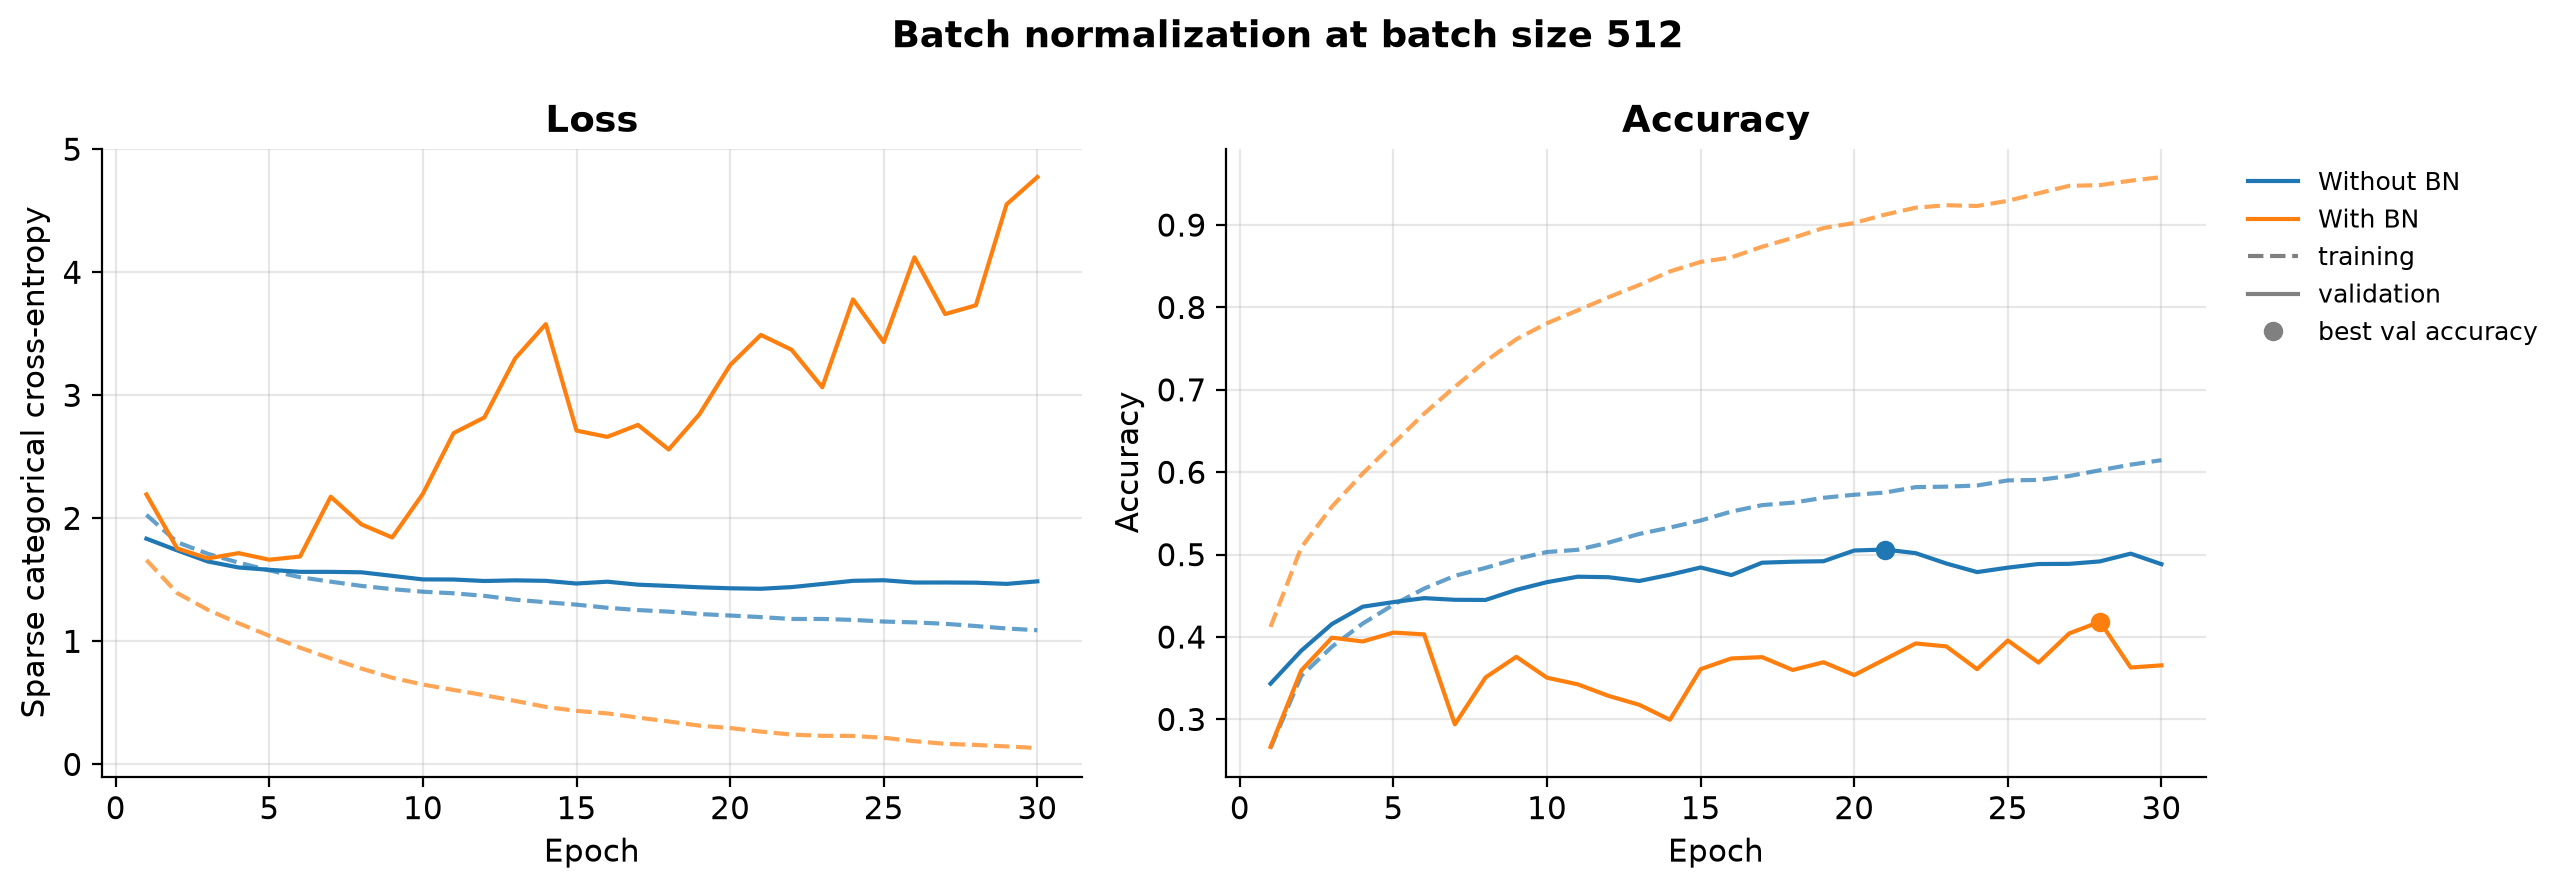

,Best val accuracy,Best epoch,Best val loss,Best val-loss epoch,Epochs to 45%,Val-loss rise (%),Gap at final epoch (pts),Val-acc noise (pts),Median s/epoch
Without BN,0.5062,21,1.4273,21,9,4.2380,12.6267,0.9202,0.9735
With BN,0.4186,28,1.6633,5,<NA>,186.9906,59.2600,2.6932,1.2073


In [19]:
bn_comparison = {"Without BN": no_bn, "With BN": bn_run}
plot_curves(bn_comparison, f"Batch normalization at batch size {SELECTED_BATCH_SIZE}")
summary_table(
    bn_comparison,
    [
        "Best val accuracy", "Best epoch", "Best val loss", "Best val-loss epoch",
        "Epochs to 45%", "Val-loss rise (%)", "Gap at final epoch (pts)",
        "Val-acc noise (pts)", "Median s/epoch",
    ],
)

**Did batch normalization help?**

**Convergence speed.** On the training set, BN made optimization much faster. Training loss after epoch 1 was 1.66 with BN against 2.03 without, and 1.05 against 1.58 after epoch 5. Training accuracy at epoch 5 was 63.5 % against 43.9 %, and by epoch 30 the BN model fits 95.8 % of the training images against 61.5 %. On the validation set the picture is reversed: the BN model **never reaches 45 %** validation accuracy, while the model without BN gets there at epoch 9. BN sped up fitting of the training data, not learning of what transfers to new images.

**Training stability.** The validation curves are much less stable with BN. Val-acc noise is 2.69 points against 0.92, and validation accuracy jumps around between about 27 % and 42 % (it drops by about 11 points between epochs 6 and 7, for example). Validation loss is jagged and climbs steadily after its epoch-5 minimum. The first-epoch validation loss is also worse (2.19 vs. 1.83), which fits the expectation that BN's running mean and variance lag behind the rapidly changing weights early in training.

**Validation performance.** Best validation accuracy is **41.86 %** with BN against **50.62 %** without, a drop of 8.8 points (about 12 standard errors). Best validation loss is 1.663 (at epoch 5) against 1.427 (at epoch 21). BN is worse on both metrics, by far more than the validation set's noise.

**Overfitting.** With BN, validation loss bottoms out at epoch 5 and then rises 187 %, to 4.77 at epoch 30, and the final train–validation gap is **59.3 points** (95.8 % vs. 36.6 %). Without BN the corresponding figures are +4.2 % and 12.6 points. BN removes much of the optimization difficulty, so Adam at learning rate 0.001 drives the 1.74-million-parameter network to memorise the training set. Nothing in this configuration (no dropout, no weight decay) pushes back. Validation loss explodes while validation accuracy only drifts down, which is consistent with the model's wrong validation predictions becoming very confident.

**Cost.** Median time per epoch rose from about 0.97 s to about 1.21 s, roughly 25 % more for the three normalization layers.

**Verdict.**
- **Stability:** no. Validation curves became noisier and validation loss diverged.
- **Convergence:** yes for training loss, which fell much faster; no for validation, where the BN model never reached the 45 % target.
- **Validation performance:** no. It was clearly worse in this setting.

**Evidence vs. assumption.** The measured facts are the curves and the table for one seed at batch size 512 with no other regularization. The explanation that faster optimization led to faster memorisation is supported by the 95.8 % training accuracy. Part of the noise may also come from a train/inference mismatch in BN's running statistics (Keras momentum 0.99 with only 88 updates per epoch); this is a plausible contributor that was not tested. BN's usual practical benefit, tolerating a higher learning rate, was not tested here because it would change a second variable. Step 5 combines BN with dropout, which addresses the overfitting seen here.

## Step 5 — Random search

**Search space.** All trials use the batch-normalized dense network (Dense → BN → ReLU → Dropout in each hidden layer) with the same width in every hidden layer. The ranges are the ones given in the assignment, unchanged:

| Hyperparameter | Values | Why it matters |
|---|---|---|
| Learning rate | 0.0001, 0.0005, 0.001, 0.005 | step size; too small under-trains in 30 epochs, too large is unstable |
| Batch size | 32, 64, 128, 256 | gradient noise and number of updates per epoch |
| Hidden layers | 2, 3, 4 | depth (capacity and optimization difficulty) |
| Units per layer | 128, 256, 512 | width (capacity) |
| Dropout | 0.0, 0.2, 0.4 | regularization strength |

The grid has 4 × 4 × 3 × 3 × 3 = 432 configurations. **Eight distinct configurations** are drawn uniformly without replacement with a NumPy generator seeded with `SEED`.

**Fixed for every trial:** 30 epochs, the same training and validation images, the same initialization seed, Adam, sparse categorical cross-entropy, and the same metrics. Trials are scored on validation accuracy only; the test set is not touched.

**Why random rather than grid.** With few trials, random search tries a different value of every hyperparameter in almost every trial, so if only one or two hyperparameters matter, each of their values is tested more often than a grid with the same budget would allow (Bergstra & Bengio, 2012).

In [20]:
SEARCH_SPACE = {
    "learning_rate": (1e-4, 5e-4, 1e-3, 5e-3),
    "batch_size": (32, 64, 128, 256),
    "layers": (2, 3, 4),
    "units": (128, 256, 512),
    "dropout": (0.0, 0.2, 0.4),
}
TABLE_COLUMNS = {
    "learning_rate": "Learning rate",
    "batch_size": "Batch size",
    "layers": "Layers",
    "units": "Hidden units",
    "dropout": "Dropout",
}


def search_config(params: dict) -> Config:
    '''Map one point of the search space to a batch-normalized `Config`.'''
    return Config(
        units=(params["units"],) * params["layers"],
        batch_norm=True,
        dropout=params["dropout"],
        learning_rate=params["learning_rate"],
        batch_size=params["batch_size"],
    )


def sample_configurations(n: int, seed: int) -> list[dict]:
    '''`n` distinct points drawn uniformly from the full grid.'''
    grid = list(itertools.product(*SEARCH_SPACE.values()))
    picks = np.random.default_rng(seed).choice(len(grid), size=n, replace=False)
    return [dict(zip(SEARCH_SPACE, grid[i])) for i in picks]


random_params = sample_configurations(N_TRIALS, SEED)
pd.DataFrame(random_params, index=pd.RangeIndex(1, N_TRIALS + 1, name="Trial")).rename(columns=TABLE_COLUMNS)

,Learning rate,Batch size,Layers,Hidden units,Dropout
Trial,,,,,
1,0.0050,256,4,512,0.2
2,0.0010,256,2,256,0.2
3,0.0050,64,4,128,0.0
4,0.0010,128,3,128,0.0
5,0.0005,128,4,256,0.4
6,0.0005,128,4,512,0.2
7,0.0001,64,3,128,0.2
8,0.0050,32,2,256,0.4


In [21]:
random_runs = [
    train(f"Random {trial}", search_config(params))[0]
    for trial, params in enumerate(random_params, start=1)
]

Random 1                 best val acc 0.4592 @ epoch 24 | min val loss 1.6058 |   82.6 s


Random 2                 best val acc 0.4952 @ epoch 15 | min val loss 1.4162 |   35.7 s


Random 3                 best val acc 0.4378 @ epoch  8 | min val loss 1.5972 |   61.2 s


Random 4                 best val acc 0.4142 @ epoch  4 | min val loss 1.6266 |   40.1 s


Random 5                 best val acc 0.5240 @ epoch 26 | min val loss 1.3513 |   73.7 s


Random 6                 best val acc 0.5206 @ epoch 29 | min val loss 1.4579 |  111.0 s


Random 7                 best val acc 0.4988 @ epoch 22 | min val loss 1.4088 |   59.1 s


Random 8                 best val acc 0.5056 @ epoch 22 | min val loss 1.3889 |  129.7 s


In [22]:
TRIAL_FORMAT = {
    "Learning rate": "{:g}",
    "Dropout": "{:g}",
    "Best validation accuracy": "{:.4f}",
    "Best val loss": "{:.4f}",
    "Train time (s)": "{:.0f}",
}


def trial_table(runs: list[Run]) -> pd.DataFrame:
    '''Table 1 layout: hyperparameters, best validation results, and a key observation per trial.'''
    rows = []
    for trial, run in enumerate(runs, start=1):
        c, s = run.config, summarize(run)
        rows.append(
            {
                "Trial": trial,
                "Learning rate": c.learning_rate,
                "Batch size": c.batch_size,
                "Layers": len(c.units),
                "Hidden units": c.units[0],
                "Dropout": c.dropout,
                "Best validation accuracy": s["Best val accuracy"],
                "Best epoch": s["Best epoch"],
                "Best val loss": s["Best val loss"],
                "Train time (s)": s["Train time (s)"],
                "Key observation": observe(run, BASELINE_ACC),
            }
        )
    return pd.DataFrame(rows).set_index("Trial")


random_table = trial_table(random_runs)
print("Table 1 — Random search (8 trials, BN on, 30 epochs each)")
random_table.style.format(TRIAL_FORMAT).highlight_max(
    subset="Best validation accuracy", color="#d4edda"
)

Table 1 — Random search (8 trials, BN on, 30 epochs each)


,Learning rate,Batch size,Layers,Hidden units,Dropout,Best validation accuracy,Best epoch,Best val loss,Train time (s),Key observation
Trial,,,,,,,,,,
1,0.005,256,4,512,0.2,0.4592,24,1.6058,83,overfits: val loss +50% after epoch 6; train-val gap 41 pts; noisy val accuracy (±2.1 pts); -2.8 pts vs baseline
2,0.001,256,2,256,0.2,0.4952,15,1.4162,36,train-val gap 28 pts; noisy val accuracy (±1.7 pts); +0.8 pts vs baseline
3,0.005,64,4,128,0,0.4378,8,1.5972,61,overfits: val loss +131% after epoch 3; train-val gap 47 pts; -4.9 pts vs baseline
4,0.001,128,3,128,0,0.4142,4,1.6266,40,overfits: val loss +157% after epoch 4; train-val gap 56 pts; -7.3 pts vs baseline
5,0.0005,128,4,256,0.4,0.5240,26,1.3513,74,"smooth convergence, small gap; +3.7 pts vs baseline"
6,0.0005,128,4,512,0.2,0.5206,29,1.4579,111,val acc peaks late (epoch 29) but val loss bottomed at epoch 13; overfits: val loss +26% after epoch 13; train-val gap 31 pts; noisy val accuracy (±2.1 pts); +3.4 pts vs baseline
7,0.0001,64,3,128,0.2,0.4988,22,1.4088,59,"smooth convergence, small gap; +1.2 pts vs baseline"
8,0.005,32,2,256,0.4,0.5056,22,1.3889,130,"smooth convergence, small gap; +1.9 pts vs baseline"


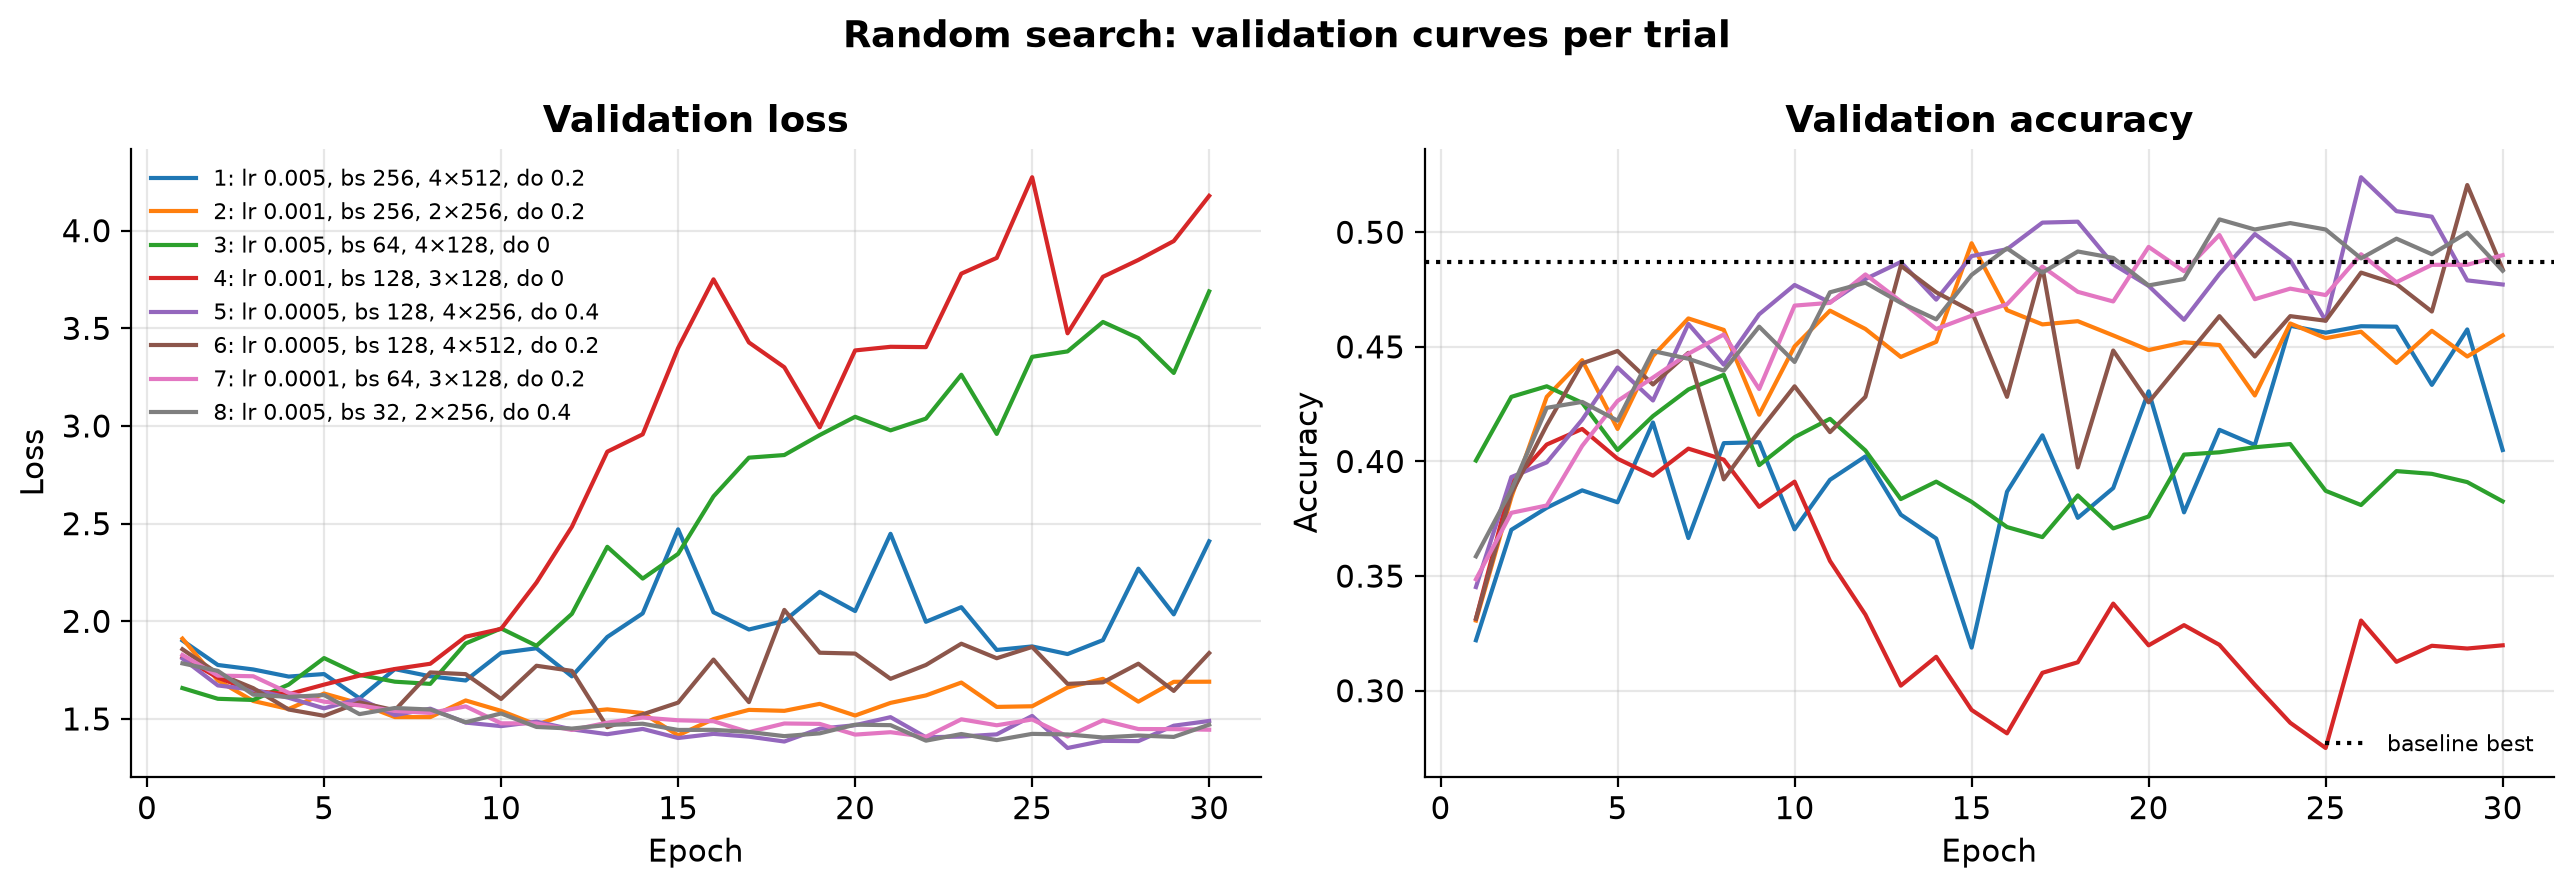

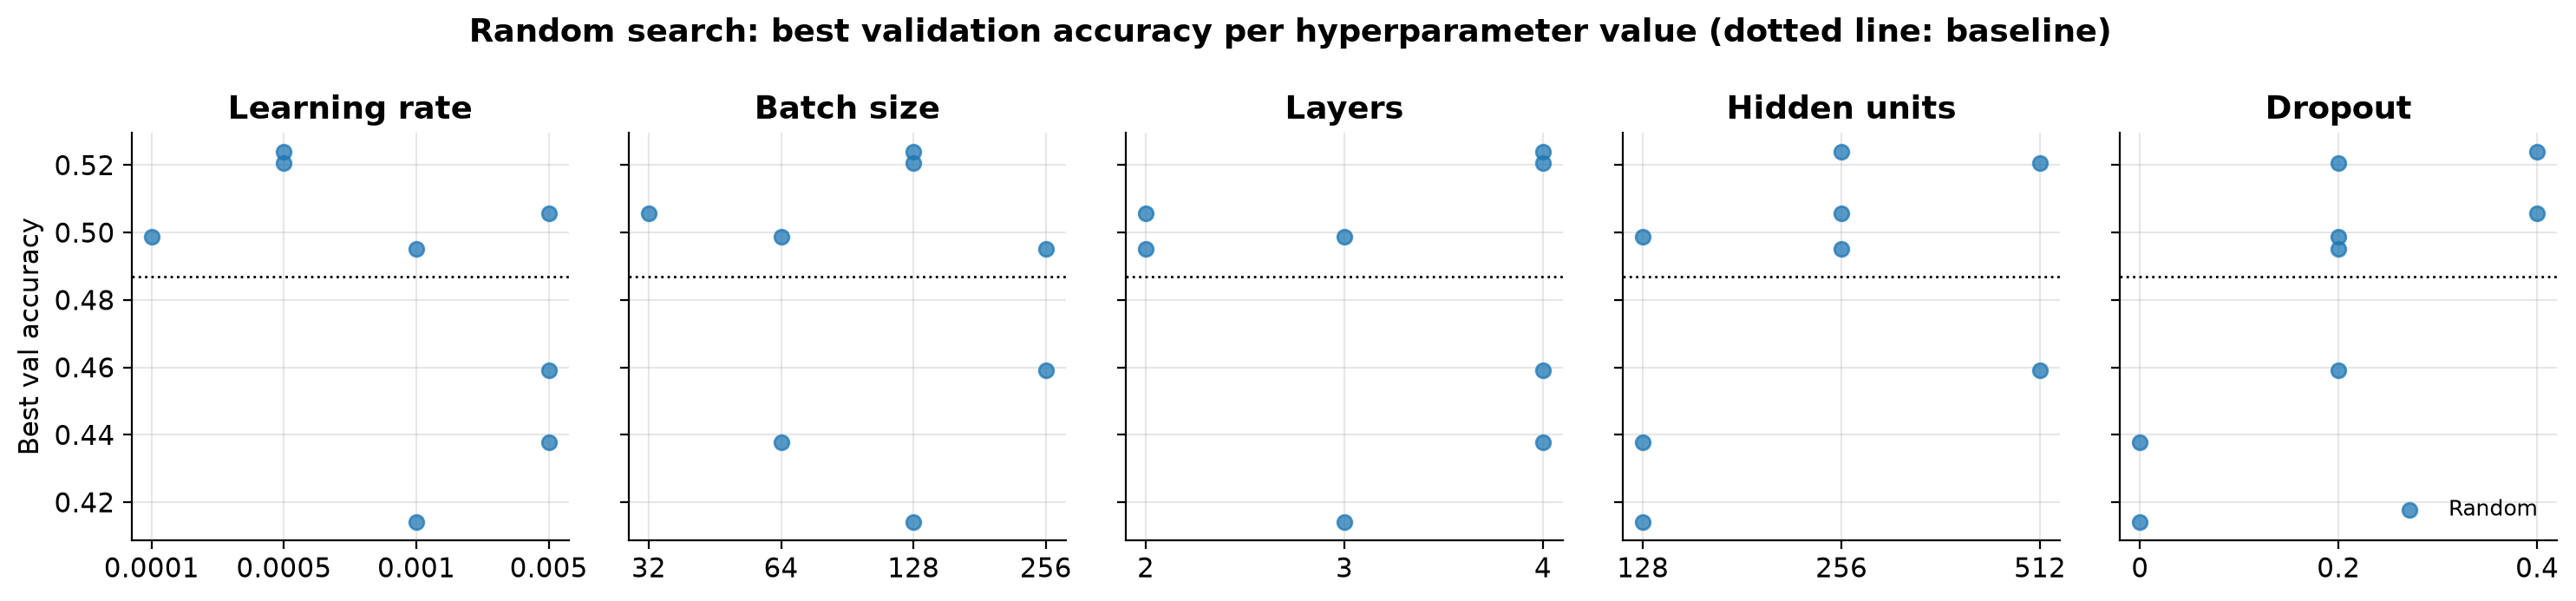

In [23]:
def plot_trial_curves(runs: list[Run], title: str) -> None:
    '''Validation loss and accuracy of every trial; a repeated configuration is drawn dashed.'''
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.5))
    for trial, run in enumerate(runs, start=1):
        h, c = run.history, run.config
        label = (
            f"{trial}: lr {c.learning_rate:g}, bs {c.batch_size}, "
            f"{len(c.units)}×{c.units[0]}, do {c.dropout:g}"
        )
        first = runs.index(run) + 1  # identity match: a repeat is the same Run object
        style = "-" if first == trial else "--"
        if first != trial:
            label += f" (repeat of {first})"
        ax_loss.plot(h.index, h["val_loss"], style, color=f"C{trial - 1}", label=label)
        ax_acc.plot(h.index, h["val_accuracy"], style, color=f"C{trial - 1}")
    ax_acc.axhline(BASELINE_ACC, color="black", ls=":", label="baseline best")
    ax_loss.set(title="Validation loss", xlabel="Epoch", ylabel="Loss")
    ax_acc.set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
    ax_loss.legend(fontsize=8)
    ax_acc.legend(fontsize=8, loc="lower right")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_marginals(tables: dict[str, pd.DataFrame], title: str) -> None:
    '''Best validation accuracy against each hyperparameter's values, one marker per search method.'''
    fig, axes = plt.subplots(1, len(SEARCH_SPACE), figsize=(15, 3.5), sharey=True)
    for (method, table), marker in zip(tables.items(), ("o", "s")):
        for ax, (param, values) in zip(axes, SEARCH_SPACE.items()):
            column = TABLE_COLUMNS[param]
            positions = table[column].map({v: i for i, v in enumerate(values)})
            ax.scatter(positions, table["Best validation accuracy"], marker=marker, alpha=0.75, label=method)
            ax.set_xticks(range(len(values)), [f"{v:g}" for v in values])
            ax.set(title=column)
    for ax in axes:
        ax.axhline(BASELINE_ACC, color="black", ls=":", lw=1)
    axes[0].set_ylabel("Best val accuracy")
    axes[-1].legend(fontsize=9, loc="lower right")
    fig.suptitle(title + " (dotted line: baseline)", fontweight="bold")
    plt.tight_layout()
    plt.show()


plot_trial_curves(random_runs, "Random search: validation curves per trial")
plot_marginals({"Random": random_table}, "Random search: best validation accuracy per hyperparameter value")

**Random-search findings.**

With 8 trials, each hyperparameter value appears only one to four times and the other four settings change at the same time, so the patterns below are tentative associations, not controlled effects.

**Strongest hyperparameters.**
- **Dropout separates good and poor trials most clearly.** The two trials without dropout (3 and 4) are the two worst (43.8 % and 41.4 %) and the most overfit: validation loss bottoms out at epoch 3–4 and then rises 131 % and 157 %, with final train–validation gaps of 47 and 56 points. This is the same memorisation the Step 4 BN model showed. Both dropout-0.4 trials score at least 50.5 %.
- **Learning rate comes second.** The two learning-rate-0.0005 trials are the top two (52.4 % and 52.1 %). Two of the three learning-rate-0.005 trials are among the three weakest (45.9 % and 43.8 %).
- **Depth, width and batch size show no clear pattern.** The 4-layer trials, for example, span the whole range from 43.8 % to 52.4 %, depending on their learning rate and dropout.

**Unstable or ineffective configurations.**
- **Trial 4** (lr 0.001, 3 × 128, no dropout) peaks at epoch 4 at 41.4 % and then degrades to 32.0 % by epoch 30. It is the clearest case of overfitting.
- **Trial 3** (lr 0.005, 4 × 128, no dropout) peaks at epoch 8, and its validation loss more than doubles.
- **Trial 1** (lr 0.005, 4 × 512, dropout 0.2) is noisy (±2.1 points), with validation loss up 50 % after epoch 6 and a 41-point gap. For the widest network at the highest learning rate, dropout 0.2 was not enough.
- **Trial 6** (lr 0.0005, 4 × 512, dropout 0.2) reaches 52.1 %, but it overfits (validation loss +26 % after epoch 13, a 31-point gap) and is noisy. Its best accuracy is a late peak at epoch 29, while its validation loss bottomed out at epoch 13.
- **Trials 7 and 8 work but are not best.** Trial 7 (lr 0.0001) is smooth, with no overfitting, gap or noise flag, and reaches 49.9 %. It shows that the smallest step size, with dropout 0.2, avoids overfitting within 30 epochs. Trial 8 shows that the highest learning rate, 0.005, can work when paired with dropout 0.4 and a small 2 × 256 network (50.6 %, smooth). It is also the most expensive trial, because batch 32 means 1,407 updates per epoch.

**Best random-search configuration: trial 5.** Learning rate 0.0005, batch size 128, 4 hidden layers of 256 units, dropout 0.4. Best validation accuracy **52.40 % at epoch 26**, where its validation loss also reaches **1.351**, the lowest of any run in the notebook. That is +3.7 points over the baseline (5.2 standard errors) and +1.8 points over the best Step 3 model (2.5 standard errors), and the run raises none of the overfitting, gap or noise flags. The epoch-26 value is a one-epoch peak, though: validation accuracy is about 46 % at epoch 25 and falls to 47.7 % by epoch 30, a late swing that the rule-based label "smooth convergence" in Table 1 does not capture. Validation loss bottoms out at the same epoch, but both metrics come from the same predictions on the same 5,000 images, so their agreement is not independent evidence. The independent check is the single test evaluation in Step 7.

## Step 6 — Bayesian optimization

**Method.** Optuna's Tree-structured Parzen Estimator (TPE) sampler (Bergstra et al., 2011; Akiba et al., 2019), a sequential model-based (Bayesian) optimizer. After each trial it splits the completed trials into a "good" group (top scores) and a "bad" group, fits a density model to the hyperparameter values in each group, and proposes the configuration that maximizes the ratio of good to bad density, which under TPE's model is equivalent to maximizing expected improvement. Unlike random search, each proposal depends on the results so far.

**Same search, same budget.** The five hyperparameters and their values are exactly the Step 5 lists (each as a categorical choice), the budget is 8 trials, and every trial goes through the same `train` function with BN on, 30 epochs, and the same data and seed. Only the method that chooses configurations differs.

**Settings that matter at this budget.**

- `n_startup_trials = 3`: TPE needs a few random observations before it can model anything. Optuna's default is 10 start-up trials, which with a budget of 8 would make every trial random and turn the comparison into random search versus random search. Three random start-ups leave five model-guided proposals.
- `multivariate = True`: models the hyperparameters jointly, so interactions such as learning rate × batch size can be captured.
- `seed = SEED`: the sampler's proposals are reproducible.
- If TPE proposes a configuration it has already evaluated, the stored result is reused (training is deterministic, so a rerun would give the same numbers) and the trial still counts toward the budget.

In [24]:
bayes_runs: list[Run] = []
bayes_cache: dict[tuple, Run] = {}
bayes_repeats: dict[int, int] = {}  # trial → earlier trial it repeats


def objective(trial: optuna.Trial) -> float:
    '''Train one proposed configuration and return its best validation accuracy.'''
    params = {name: trial.suggest_categorical(name, values) for name, values in SEARCH_SPACE.items()}
    number, key = trial.number + 1, tuple(params.values())
    if key in bayes_cache:
        run = bayes_cache[key]
        bayes_repeats[number] = bayes_runs.index(run) + 1
        print(f"Bayesian {number:<15} repeats trial {bayes_repeats[number]} (not retrained)")
    else:
        run, _ = train(f"Bayesian {number}", search_config(params))
        bayes_cache[key] = run
    bayes_runs.append(run)
    trial.set_user_attr("best_epoch", run.best_epoch)
    return run.best_val_accuracy  # NaN marks the trial as failed in Optuna


study = optuna.create_study(
    study_name="cifar10_dense_bn",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        n_startup_trials=N_STARTUP_TRIALS, multivariate=True, seed=SEED
    ),
)
study.optimize(objective, n_trials=N_TRIALS)

Bayesian 1               best val acc 0.4984 @ epoch 26 | min val loss 1.4030 |   28.1 s


Bayesian 2               best val acc 0.4690 @ epoch 22 | min val loss 1.5172 |   56.2 s


Bayesian 3               best val acc 0.4938 @ epoch 28 | min val loss 1.4145 |  104.1 s
Bayesian 4               repeats trial 1 (not retrained)


Bayesian 5               best val acc 0.4076 @ epoch  2 | min val loss 1.6437 |   45.6 s


Bayesian 6               best val acc 0.4532 @ epoch 17 | min val loss 1.5246 |   38.0 s


Bayesian 7               best val acc 0.4766 @ epoch 22 | min val loss 1.4525 |   46.1 s


Bayesian 8               best val acc 0.5090 @ epoch 20 | min val loss 1.4447 |   98.8 s


In [25]:
bayes_table = trial_table(bayes_runs)
bayes_table.insert(
    0, "Proposed by",
    ["random start-up"] * N_STARTUP_TRIALS + ["TPE"] * (N_TRIALS - N_STARTUP_TRIALS),
)
bayes_table.insert(1, "Optuna state", [t.state.name for t in study.trials])
for trial, earlier in bayes_repeats.items():
    bayes_table.loc[trial, "Key observation"] = (
        f"repeat of trial {earlier}; " + bayes_table.loc[trial, "Key observation"]
    )

failed = [t.number + 1 for t in study.trials if t.state.name == "FAIL"]
unstable = [i for i, run in enumerate(bayes_runs, start=1) if is_unstable(run)]
print("Bayesian optimization (TPE, 8 trials, BN on, 30 epochs each)")
print(f"Failed trials: {failed or 'none'} | unstable trials: {unstable or 'none'}")
print(
    f"Best trial: {study.best_trial.number + 1}, {study.best_params}, "
    f"best val acc {study.best_value:.4f} at epoch {study.best_trial.user_attrs['best_epoch']}"
)
bayes_table.style.format(TRIAL_FORMAT).highlight_max(
    subset="Best validation accuracy", color="#d4edda"
)

Bayesian optimization (TPE, 8 trials, BN on, 30 epochs each)
Failed trials: none | unstable trials: [2, 5, 6, 8]
Best trial: 8, {'learning_rate': 0.001, 'batch_size': 64, 'layers': 3, 'units': 256, 'dropout': 0.2}, best val acc 0.5090 at epoch 20


,Proposed by,Optuna state,Learning rate,Batch size,Layers,Hidden units,Dropout,Best validation accuracy,Best epoch,Best val loss,Train time (s),Key observation
Trial,,,,,,,,,,,,
1,random start-up,COMPLETE,0.0005,256,3,128,0.4,0.4984,26,1.4030,28,"smooth convergence, small gap; +1.1 pts vs baseline"
2,random start-up,COMPLETE,0.005,256,2,512,0.4,0.4690,22,1.5172,56,train-val gap 28 pts; noisy val accuracy (±1.8 pts); -1.8 pts vs baseline
3,random start-up,COMPLETE,0.0001,32,3,128,0.4,0.4938,28,1.4145,104,still improving at the last epoch; +0.7 pts vs baseline
4,TPE,COMPLETE,0.0005,256,3,128,0.4,0.4984,26,1.4030,28,"repeat of trial 1; smooth convergence, small gap; +1.1 pts vs baseline"
5,TPE,COMPLETE,0.0005,256,4,256,0,0.4076,2,1.6437,46,overfits: val loss +188% after epoch 2; train-val gap 63 pts; noisy val accuracy (±1.6 pts); -7.9 pts vs baseline
6,TPE,COMPLETE,0.0005,128,2,128,0.2,0.4532,17,1.5246,38,train-val gap 19 pts; noisy val accuracy (±1.7 pts); -3.4 pts vs baseline
7,TPE,COMPLETE,0.001,128,4,128,0.4,0.4766,22,1.4525,46,"smooth convergence, small gap; -1.0 pts vs baseline"
8,TPE,COMPLETE,0.001,64,3,256,0.2,0.5090,20,1.4447,99,train-val gap 24 pts; noisy val accuracy (±1.6 pts); +2.2 pts vs baseline


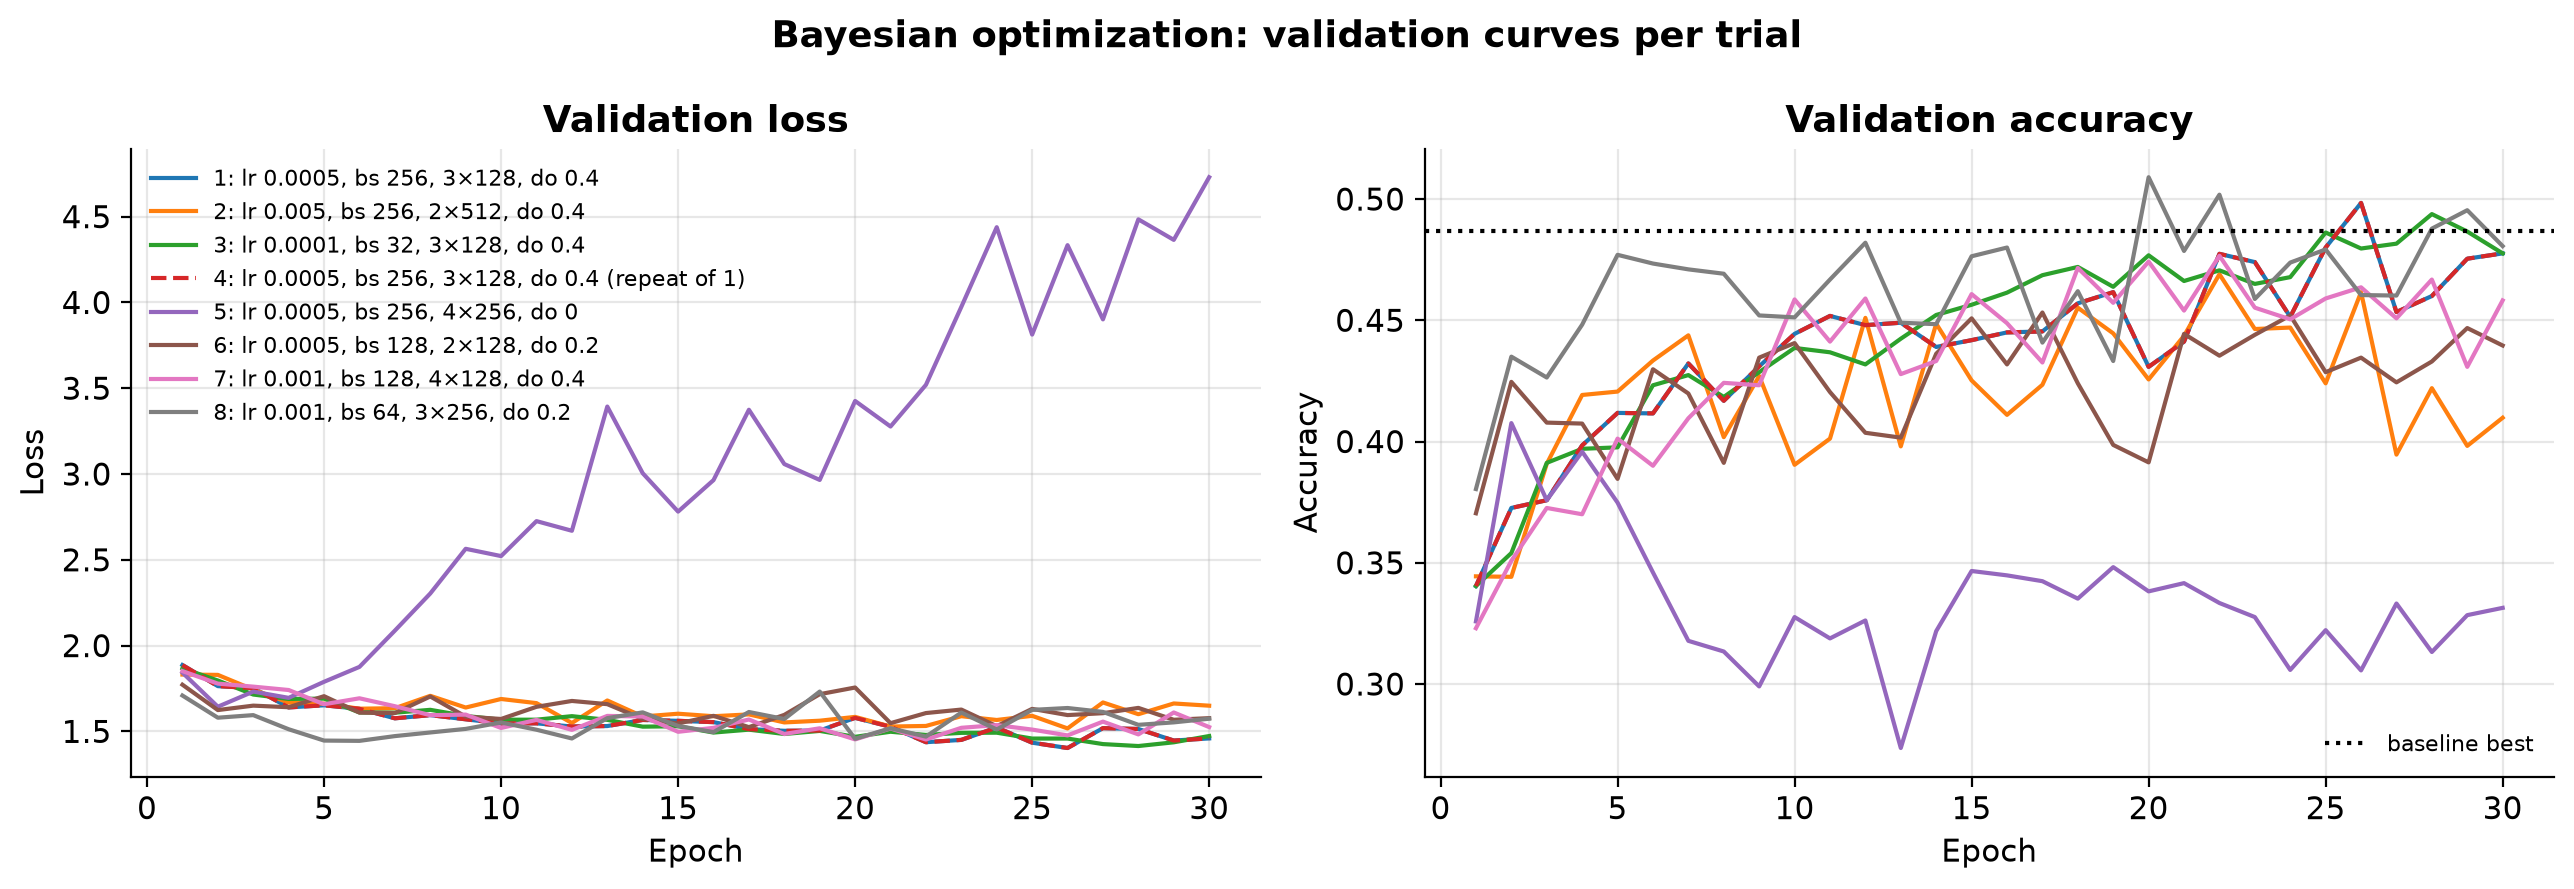

In [26]:
plot_trial_curves(bayes_runs, "Bayesian optimization: validation curves per trial")

### Random search vs. Bayesian optimization

Both methods had 8 trials over the same space. A configuration counts as **strong** when its best validation accuracy is within one standard error (≈ 0.71 points) of the best result found by either method, the resolution of the validation set.

In [27]:
searches = {"Random search": random_runs, "Bayesian (TPE)": bayes_runs}
overall_best = max(run.best_val_accuracy for runs in searches.values() for run in runs)


def search_profile(runs: list[Run]) -> dict[str, float]:
    '''Outcome, speed, stability, and cost of one search.'''
    scores = np.array([run.best_val_accuracy for run in runs])
    strong = np.flatnonzero(scores >= overall_best - VAL_SE)
    trained = list({id(run): run for run in runs}.values())  # repeated trials were not retrained
    return {
        "Best val accuracy": scores.max(),
        "Trial of best": int(scores.argmax()) + 1,
        "Trials to a strong config": int(strong[0]) + 1 if len(strong) else float("nan"),
        "Strong configs found": len(strong),
        "Mean val accuracy": scores.mean(),
        "Std val accuracy (pts)": 100 * scores.std(ddof=1),
        "Worst val accuracy": scores.min(),
        "Trials above baseline": int((scores > BASELINE_ACC).sum()),
        "Unstable trials": sum(is_unstable(run) for run in runs),
        "Distinct configs trained": len(trained),
        "Total train time (min)": sum(run.history["seconds"].sum() for run in trained) / 60,
        "Total weight updates (k)": sum(
            len(run.history) * run.config.updates_per_epoch for run in trained
        ) / 1e3,
    }


comparison = pd.DataFrame({name: search_profile(runs) for name, runs in searches.items()})
print(f"Strong = best val accuracy ≥ {overall_best:.4f} − {VAL_SE:.4f} = {overall_best - VAL_SE:.4f}")
comparison

Strong = best val accuracy ≥ 0.5240 − 0.0071 = 0.5169


,Random search,Bayesian (TPE)
Best val accuracy,0.5240,0.5090
Trial of best,5.0000,8.0000
Trials to a strong config,5.0000,NaN
Strong configs found,2.0000,0.0000
Mean val accuracy,0.4819,0.4758
Std val accuracy (pts),4.0245,3.3073
Worst val accuracy,0.4142,0.4076
Trials above baseline,5.0000,4.0000
Unstable trials,5.0000,4.0000
Distinct configs trained,8.0000,7.0000


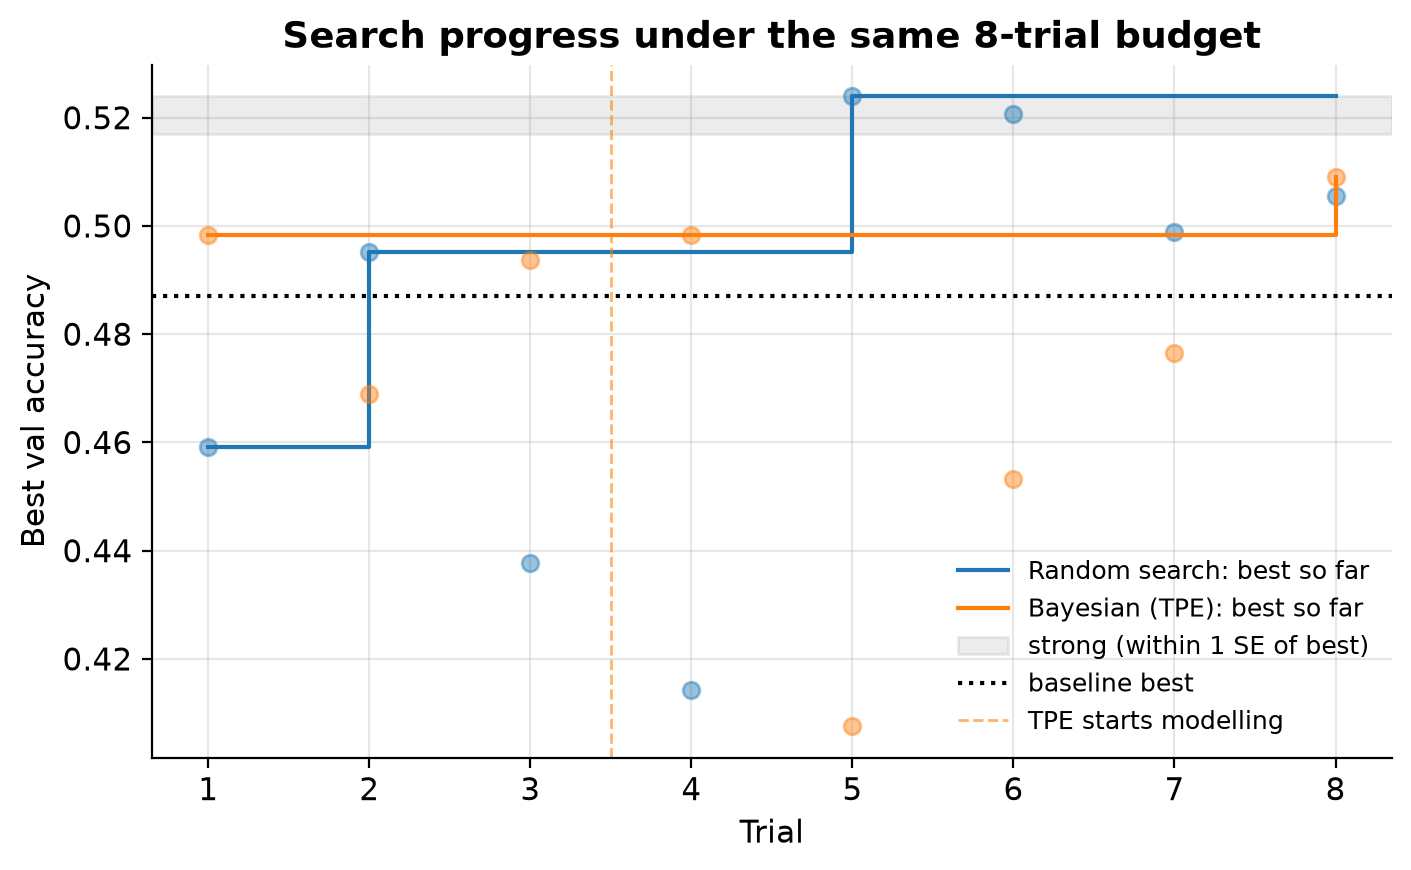

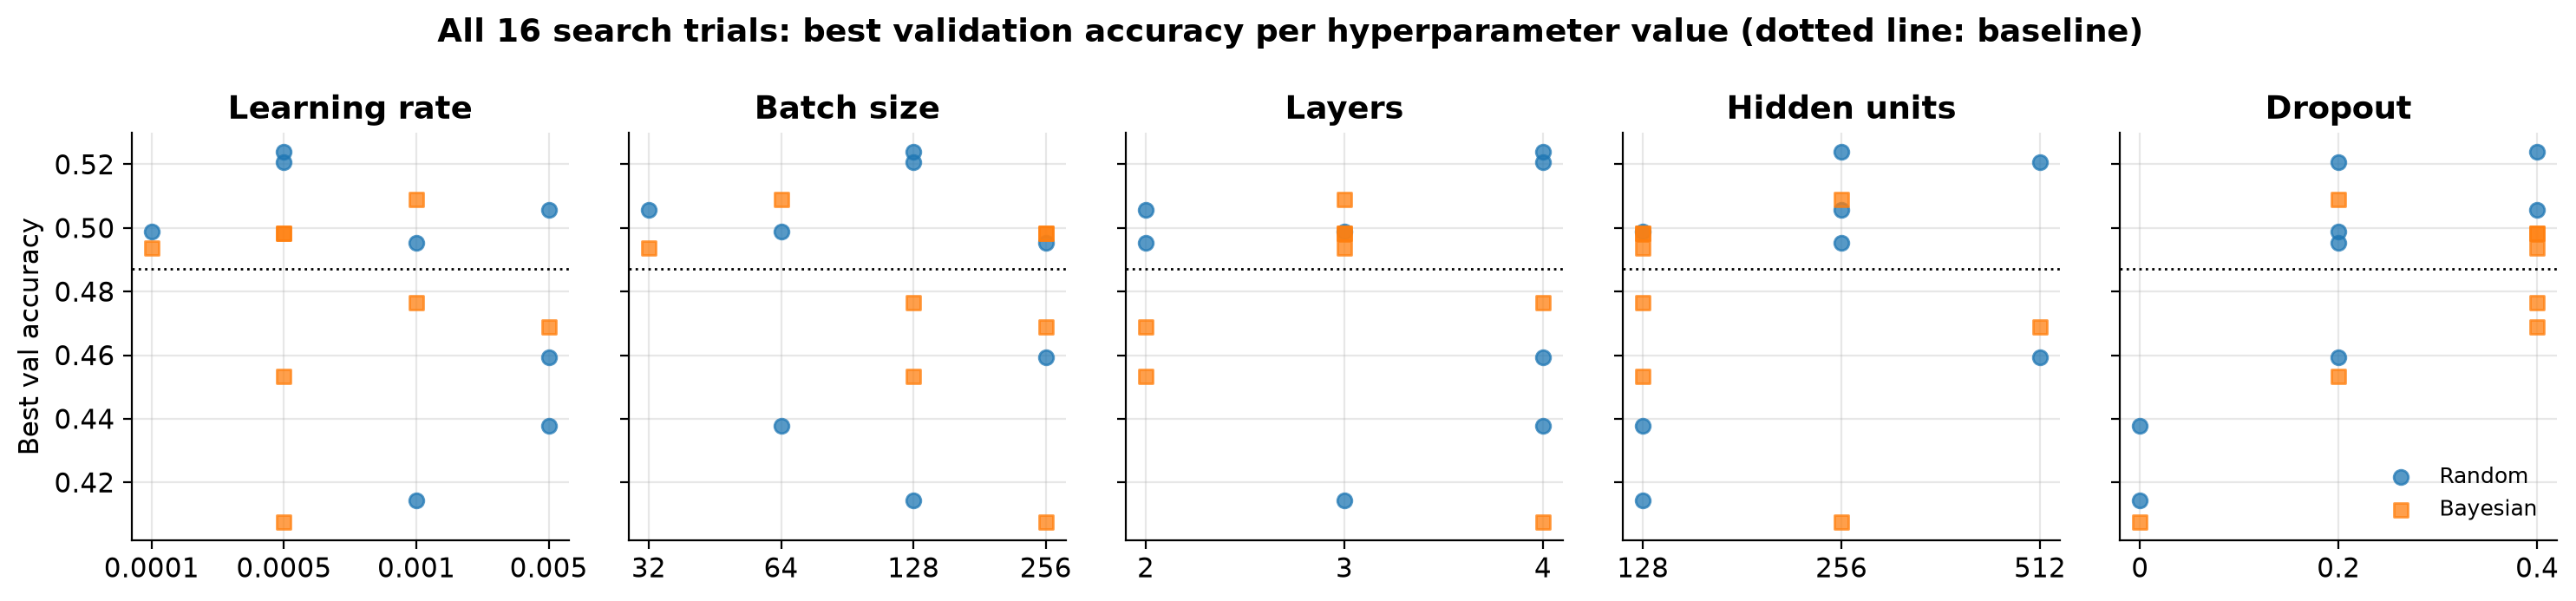

In [28]:
fig, ax = plt.subplots()
for colour, (name, runs) in enumerate(searches.items()):
    scores = np.array([run.best_val_accuracy for run in runs])
    trials = np.arange(1, len(scores) + 1)
    ax.plot(trials, scores, "o", color=f"C{colour}", alpha=0.45)
    ax.step(trials, np.maximum.accumulate(scores), where="post", color=f"C{colour}",
            label=f"{name}: best so far")
ax.axhspan(overall_best - VAL_SE, overall_best, color="grey", alpha=0.15,
           label="strong (within 1 SE of best)")
ax.axhline(BASELINE_ACC, color="black", ls=":", label="baseline best")
ax.axvline(N_STARTUP_TRIALS + 0.5, color="C1", ls="--", lw=1, alpha=0.6, label="TPE starts modelling")
ax.set(title="Search progress under the same 8-trial budget", xlabel="Trial",
       ylabel="Best val accuracy", xticks=range(1, N_TRIALS + 1))
ax.legend(fontsize=9, loc="lower right")
plt.show()

plot_marginals(
    {"Random": random_table, "Bayesian": bayes_table},
    "All 16 search trials: best validation accuracy per hyperparameter value",
)

**Comparing the two methods.**

**Best validation accuracy.** Random search found **52.40 %** (trial 5) and Bayesian optimization **50.90 %** (trial 8). The 1.5-point difference is about 2.1 standard errors, which is outside the one-standard-error tie band used here, so in this run random search found the better configuration. With one seed per trial and the best of only 8 draws, it is not a decisive difference.

**Trials needed for a strong configuration.** "Strong" means at least 51.69 % (within one standard error of the best). Random search reached that at trial 5 and found two strong configurations (trials 5 and 6). TPE found none in its 8 trials. In the best-so-far plot, TPE's best was set by its first random start-up trial (49.84 %) and improved only at trial 8.

**How TPE used its five model-guided trials.** Three observations are too few for a reliable density model, and it shows:
- **Trial 4** proposed exactly the configuration of trial 1, the best start-up trial. That used one eighth of the budget to learn nothing new (the stored result was reused, not retrained).
- **Trial 5** kept trial 1's learning rate and batch size but switched to 4 × 256 with no dropout. It was the worst trial of either search (40.8 %, validation loss +188 % after epoch 2).
- **Trials 6–8** all used dropout ≥ 0.2 and reached 45.3 %, 47.7 % and 50.9 %. Avoiding no-dropout settings after trial 5 is consistent with TPE learning from that failure, but five guided proposals were not enough to reach the region random search sampled by chance.

**Stability of the search.** The spread of TPE's scores is slightly narrower (standard deviation 3.31 vs. 4.02 points), but the duplicate trial contributes to that. The worst trials are similar (40.8 % vs. 41.4 %), and random search has the higher mean (48.2 % vs. 47.6 %). TPE has fewer unstable trials (4 vs. 5) but also fewer trials above the baseline (4 vs. 5). No trial in either search failed with a NaN loss.

**Computational effort.** TPE trained 7 distinct configurations in about 7 minutes (100,000 weight updates). Random search trained 8 in about 10 minutes (127,000 updates). The difference comes from which settings each method happened to try: random search's two most expensive trials were batch 32 (trial 8) and the 4 × 512 network (trial 6), and TPE's duplicate cost nothing. TPE's own computation is negligible next to training.

**Conclusion.** Under the same 8-trial budget, random search found the higher score and the only strong configurations, and TPE was cheaper and wasted one trial on a repeat. This is one run with one seed per configuration: random search's best draw (learning rate 0.0005 with dropout 0.4) was partly luck, and TPE had only five model-guided proposals after three random ones. The comparison shows what happened here, not that random search is better in general. Model-based search is expected to pay off with budgets large enough for its density model to have many observations; that expectation was not tested here.

## Step 7 — Select and evaluate the final model

**Selection rule.** The final configuration is the run with the highest best validation accuracy across **all** completed experiments: the baseline, the three batch sizes, the BN model, and all 16 search trials. Ties are broken by the lower best validation loss. The runs within one standard error of the winner are listed too, because picking the maximum of 19 noisy scores slightly overstates the winner's true accuracy (the winner's curse).

**Training length.** The selected configuration is **retrained** from the same seed for exactly its best epoch, the epoch count informed by validation. Because the seed is reset, the initial weights and shuffling order are the same as in the original run, and deterministic kernels make the first *k* epochs identical, so the retrained model reproduces the best-epoch model. The cell below checks this by comparing the retrained model's final validation accuracy with the recorded best.

In [29]:
all_runs = {
    "Baseline": baseline,
    **{f"Batch {size}": run for size, run in batch_runs.items() if size != BASELINE_BATCH_SIZE},
    "Batch norm": bn_run,
    **{f"Random {i}": run for i, run in enumerate(random_runs, start=1)},
    **{f"Bayesian {i}": run for i, run in enumerate(bayes_runs, start=1) if i not in bayes_repeats},
}
candidates = pd.DataFrame(
    [
        {
            "Run": name,
            "Configuration": run.config.describe(),
            "Best val accuracy": run.best_val_accuracy,
            "Best val loss": run.history["val_loss"].min(),
            "Best epoch": run.best_epoch,
        }
        for name, run in all_runs.items()
    ]
).set_index("Run").sort_values(["Best val accuracy", "Best val loss"], ascending=[False, True])
candidates["Within 1 SE of best"] = (
    candidates["Best val accuracy"] >= candidates["Best val accuracy"].iloc[0] - VAL_SE
)
selected_name = candidates.index[0]
selected = all_runs[selected_name]
print(f"Selected: {selected_name} — {selected.config.describe()}")
candidates.head(8)

Selected: Random 5 — 4 × [256-256-256-256], BN on, dropout 0.4, lr 0.0005, batch 128


,Configuration,Best val accuracy,Best val loss,Best epoch,Within 1 SE of best
Run,,,,,
Random 5,"4 × [256-256-256-256], BN on, dropout 0.4, lr ...",0.5240,1.3513,26,True
Random 6,"4 × [512-512-512-512], BN on, dropout 0.2, lr ...",0.5206,1.4579,29,True
Bayesian 8,"3 × [256-256-256], BN on, dropout 0.2, lr 0.00...",0.5090,1.4447,20,False
Batch 512,"3 × [512-256-128], BN off, dropout 0, lr 0.001...",0.5062,1.4273,21,False
Random 8,"2 × [256-256], BN on, dropout 0.4, lr 0.005, b...",0.5056,1.3889,22,False
Random 7,"3 × [128-128-128], BN on, dropout 0.2, lr 0.00...",0.4988,1.4088,22,False
Bayesian 1,"3 × [128-128-128], BN on, dropout 0.4, lr 0.00...",0.4984,1.4030,26,False
Random 2,"2 × [256-256], BN on, dropout 0.2, lr 0.001, b...",0.4952,1.4162,15,False


In [30]:
final_config = replace(selected.config, epochs=selected.best_epoch)
final_run, final_model = train("Final (retrained)", final_config)
retrained_val = final_run.history["val_accuracy"].iloc[-1]
print(
    f"Validation accuracy after {final_config.epochs} epochs: {retrained_val:.4f} "
    f"(original run's best: {selected.best_val_accuracy:.4f}; "
    f"reproduced: {np.isclose(retrained_val, selected.best_val_accuracy, atol=1e-4)})"
)

pd.Series(
    {
        "Network depth (hidden layers)": len(final_config.units),
        "Hidden units per layer": "-".join(map(str, final_config.units)),
        "Batch normalization": "on" if final_config.batch_norm else "off",
        "Dropout rate": f"{final_config.dropout:g}",
        "Learning rate": f"{final_config.learning_rate:g}",
        "Batch size": final_config.batch_size,
        "Training epochs": final_config.epochs,
        "Selected from": selected_name,
    },
    name="Final model",
).to_frame()

Final (retrained)        best val acc 0.5240 @ epoch 26 | min val loss 1.3513 |   64.6 s
Validation accuracy after 26 epochs: 0.5240 (original run's best: 0.5240; reproduced: True)


,Final model
Network depth (hidden layers),4
Hidden units per layer,256-256-256-256
Batch normalization,on
Dropout rate,0.4
Learning rate,0.0005
Batch size,128
Training epochs,26
Selected from,Random 5


### Single evaluation on the test set

The configuration above is now fixed. The test set is used here once: one prediction pass over the 10,000 test images, from which test loss, test accuracy, per-class accuracy, and the confusion matrix are all computed. None of these numbers feeds back into any choice above.

In [31]:
test_probs = final_model.predict(data.test.X, batch_size=1024, verbose=0)
test_loss = float(keras.losses.SparseCategoricalCrossentropy()(data.test.y, test_probs))
test_pred = test_probs.argmax(axis=1)
test_acc = float((test_pred == data.test.y).mean())

pd.Series(
    {
        "Final configuration": f"{final_config.describe()}, {final_config.epochs} epochs",
        "Best validation accuracy": f"{selected.best_val_accuracy:.4f}",
        "Test accuracy": f"{test_acc:.4f}",
        "Test loss": f"{test_loss:.4f}",
        "Validation − test accuracy (pts)": f"{100 * (selected.best_val_accuracy - test_acc):+.2f}",
    },
    name="Final model",
).to_frame()

,Final model
Final configuration,"4 × [256-256-256-256], BN on, dropout 0.4, lr ..."
Best validation accuracy,0.5240
Test accuracy,0.5201
Test loss,1.3437
Validation − test accuracy (pts),+0.39


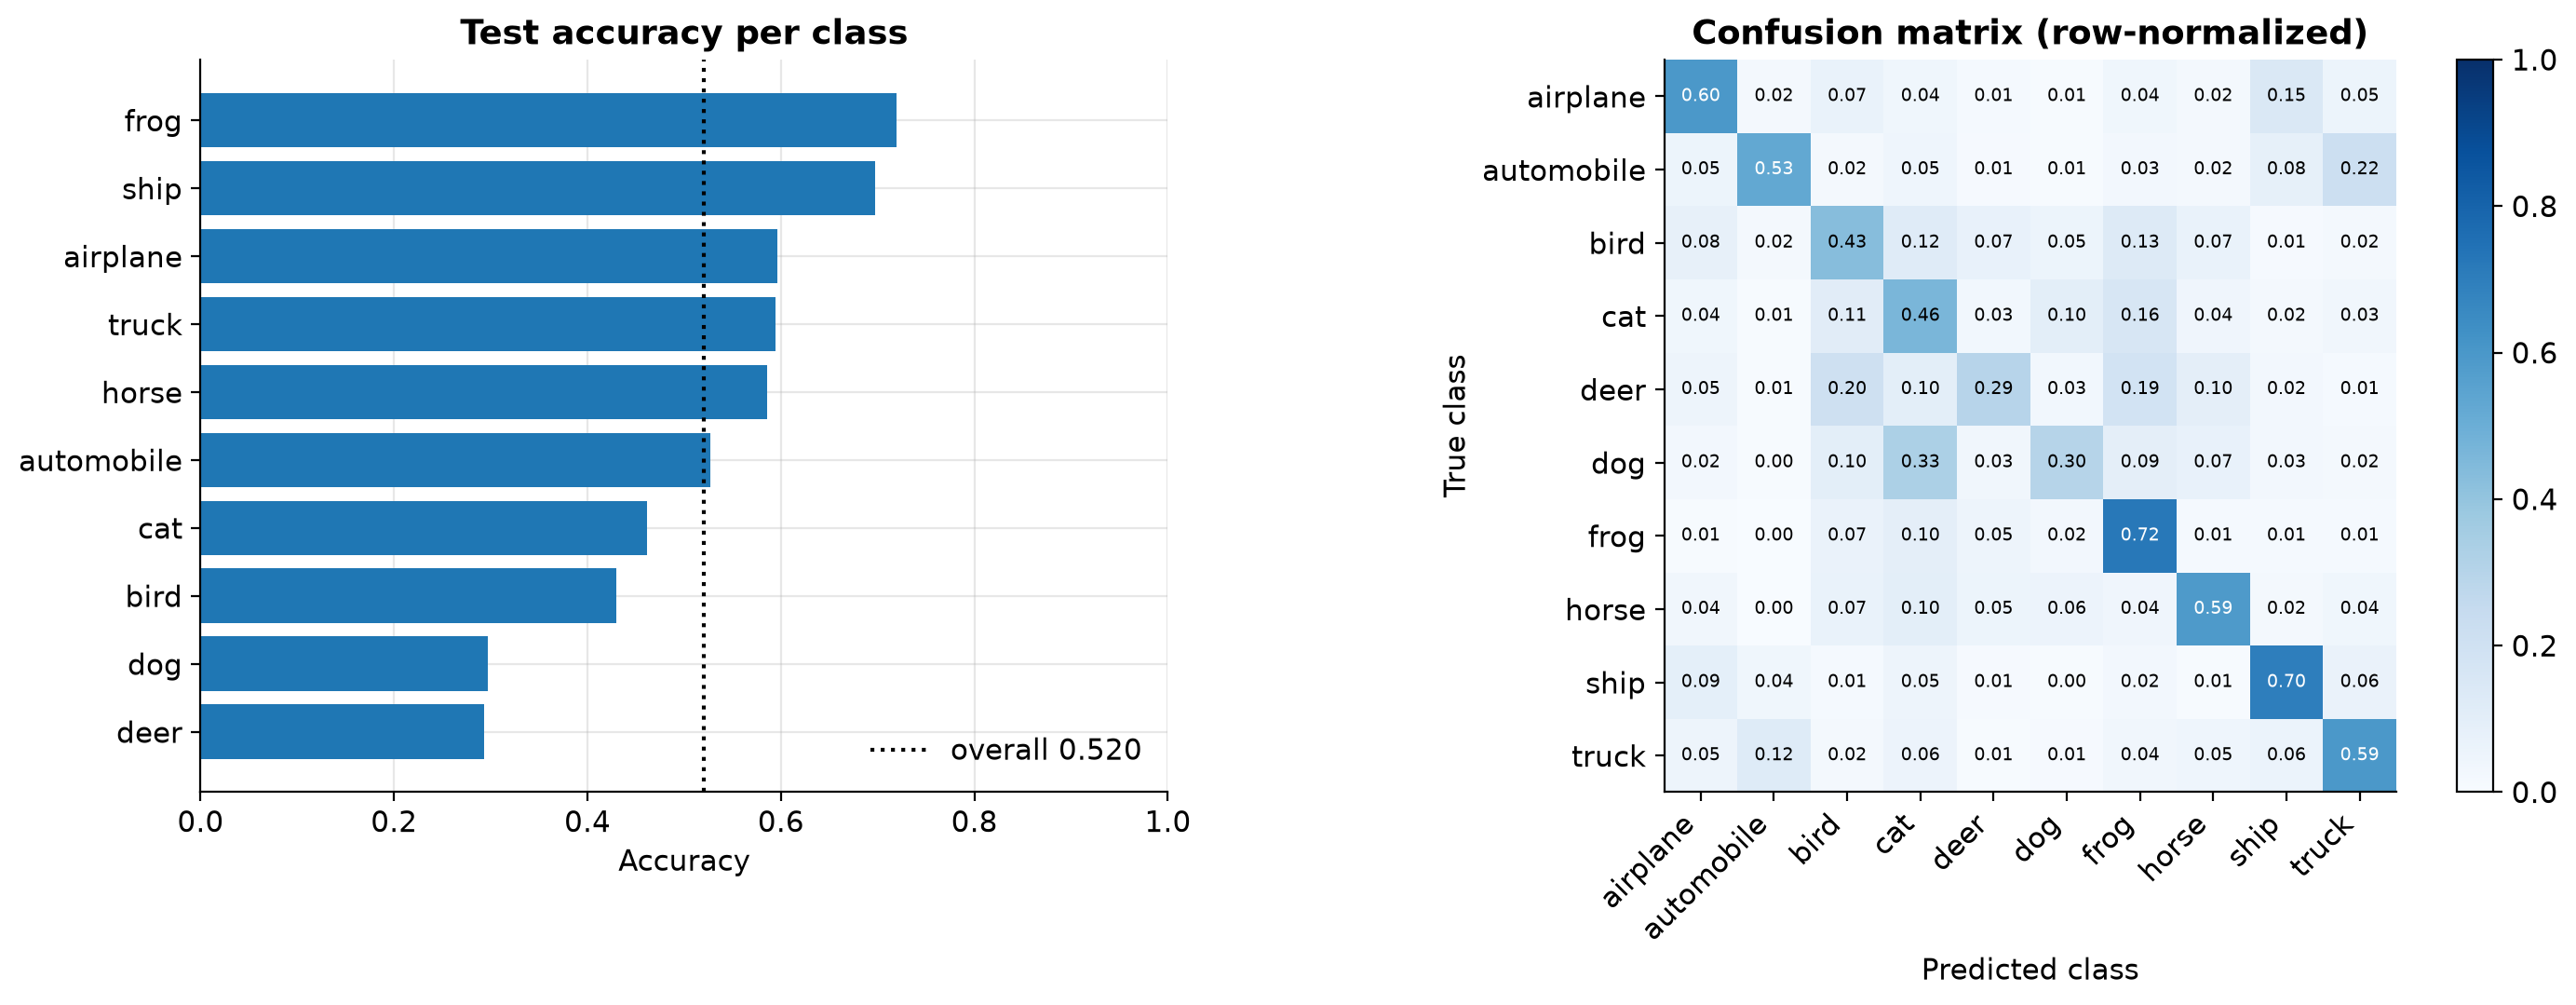

In [32]:
matrix = confusion_matrix(data.test.y, test_pred, labels=range(10))
per_class = matrix.diagonal() / matrix.sum(axis=1)
normalized = matrix / matrix.sum(axis=1, keepdims=True)

fig, (ax_bar, ax_cm) = plt.subplots(
    1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.25]}
)
order = np.argsort(per_class)
ax_bar.barh(np.array(CLASS_NAMES)[order], per_class[order], color="C0")
ax_bar.axvline(test_acc, color="black", ls=":", label=f"overall {test_acc:.3f}")
ax_bar.set(title="Test accuracy per class", xlabel="Accuracy", xlim=(0, 1))
ax_bar.legend(loc="lower right")

image = ax_cm.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
ax_cm.set_xticks(range(10), CLASS_NAMES, rotation=45, ha="right")
ax_cm.set_yticks(range(10), CLASS_NAMES)
ax_cm.grid(False)
for i, j in itertools.product(range(10), range(10)):
    ax_cm.text(j, i, f"{normalized[i, j]:.2f}", ha="center", va="center", fontsize=7,
               color="white" if normalized[i, j] > 0.5 else "black")
ax_cm.set(title="Confusion matrix (row-normalized)", xlabel="Predicted class", ylabel="True class")
fig.colorbar(image, ax=ax_cm, fraction=0.046)
plt.tight_layout()
plt.show()

**Final model.**

**Selected configuration: Random trial 5.** 4 hidden layers × 256 units, Dense → BN → ReLU → Dropout 0.4, Adam with learning rate 0.0005, batch size 128. It has the highest best validation accuracy of the 19 distinct runs (**52.40 %**) and also the lowest best validation loss of all runs (1.351), so the two validation metrics agree. The only other run within one standard error is Random trial 6 (52.06 %, 0.34 points lower, about 0.5 SE). Trial 5 is also the better choice on every secondary criterion:
- lower validation loss (1.351 vs. 1.458)
- a final train–validation gap below the 15-point flag, against 31 points for trial 6
- no instability flag
- about 0.99 million parameters against 2.37 million
- about 74 s of training against about 111 s

The highest-accuracy rule and the simpler, more stable choice point to the same model.

**Training approach.** The configuration was **retrained** from the same seed for exactly its best epoch count, 26 epochs. The retrained model's validation accuracy after epoch 26 is 0.5240, identical to the original run's best, so the evaluated model is the best-epoch model itself.

**Test result.** Test accuracy **52.01 %**, test loss **1.344**, against a best validation accuracy of 52.40 % and validation loss of 1.351. The 0.39-point drop is well inside the noise of the two estimates: one standard error is about 0.71 points on validation and 0.50 points on the 10,000 test images, about 0.87 points for their difference. A small drop is expected, because taking the maximum over 19 runs makes the winning validation score slightly optimistic. A drop this small is consistent with the selection not having overfit the validation set. The test result was not used to revise any choice.

**Diagnostics.**
- **Easiest classes:** frog (71.9 %), ship (69.7 %), airplane (59.6 %), truck (59.4 %) and horse (58.6 %).
- **Hardest classes:** deer (29.3 %), dog (29.7 %), bird (43.0 %) and cat (46.2 %).
- **Largest confusions:** dog → cat (33.0 %, so more dogs are labelled cat than dog), automobile → truck (21.6 %), deer → bird (20.4 %), deer → frog (18.7 %), cat → frog (16.2 %) and airplane → ship (14.8 %).

These are the errors a flattened-pixel model should make. The easy classes have distinctive colour and global layout, such as ships and airplanes against blue sky or water. The same cue causes the airplane → ship confusion. Frogs have characteristic green and brown textures. The hard classes are the four-legged animals and birds against similar natural backgrounds. Cats and dogs differ mainly in local shape (ears, snout, body outline) that can appear anywhere in the image, which is exactly the translation-invariant local structure a dense network cannot represent. The confusion counts are measured. The explanations are hypotheses consistent with them, not tested here (for example, against a colour-histogram baseline).

## Step 8 — Comparative analysis

Table 2 collects the reference points of the tuning process. Only the final selected model has a test accuracy.

In [33]:
best_random = max(random_runs, key=lambda run: run.best_val_accuracy)
best_bayes = max(bayes_runs, key=lambda run: run.best_val_accuracy)
milestones = {
    "Baseline": baseline,
    f"Best batch size ({SELECTED_BATCH_SIZE})": batch_runs[SELECTED_BATCH_SIZE],
    "Batch-normalized model": bn_run,
    "Best random-search model": best_random,
    "Best Bayesian model": best_bayes,
}
table2 = pd.DataFrame(
    [
        {
            "Configuration": name,
            "Settings": run.config.describe(),
            "Best validation accuracy": run.best_val_accuracy,
            "Best epoch": run.best_epoch,
            "Key observation": observe(run, None if run is baseline else BASELINE_ACC),
            "Test accuracy": "—",
        }
        for name, run in milestones.items()
    ]
    + [
        {
            "Configuration": "Final selected model",
            "Settings": f"{final_config.describe()}, retrained {final_config.epochs} epochs",
            "Best validation accuracy": selected.best_val_accuracy,
            "Best epoch": selected.best_epoch,
            "Key observation": f"selected from {selected_name}; test loss {test_loss:.4f}",
            "Test accuracy": f"{test_acc:.4f}",
        }
    ]
).set_index("Configuration")
print("Table 2 — Summary comparison")
table2.style.format({"Best validation accuracy": "{:.4f}"})

Table 2 — Summary comparison


,Settings,Best validation accuracy,Best epoch,Key observation,Test accuracy
Configuration,,,,,
Baseline,"3 × [512-256-128], BN off, dropout 0, lr 0.001, batch 128",0.4870,28,val acc peaks late (epoch 28) but val loss bottomed at epoch 11,—
Best batch size (512),"3 × [512-256-128], BN off, dropout 0, lr 0.001, batch 512",0.5062,21,"smooth convergence, small gap; +1.9 pts vs baseline",—
Batch-normalized model,"3 × [512-256-128], BN on, dropout 0, lr 0.001, batch 512",0.4186,28,val acc peaks late (epoch 28) but val loss bottomed at epoch 5; overfits: val loss +187% after epoch 5; train-val gap 59 pts; noisy val accuracy (±2.7 pts); -6.8 pts vs baseline,—
Best random-search model,"4 × [256-256-256-256], BN on, dropout 0.4, lr 0.0005, batch 128",0.5240,26,"smooth convergence, small gap; +3.7 pts vs baseline",—
Best Bayesian model,"3 × [256-256-256], BN on, dropout 0.2, lr 0.001, batch 64",0.5090,20,train-val gap 24 pts; noisy val accuracy (±1.6 pts); +2.2 pts vs baseline,—
Final selected model,"4 × [256-256-256-256], BN on, dropout 0.4, lr 0.0005, batch 128, retrained 26 epochs",0.5240,26,selected from Random 5; test loss 1.3437,0.5201


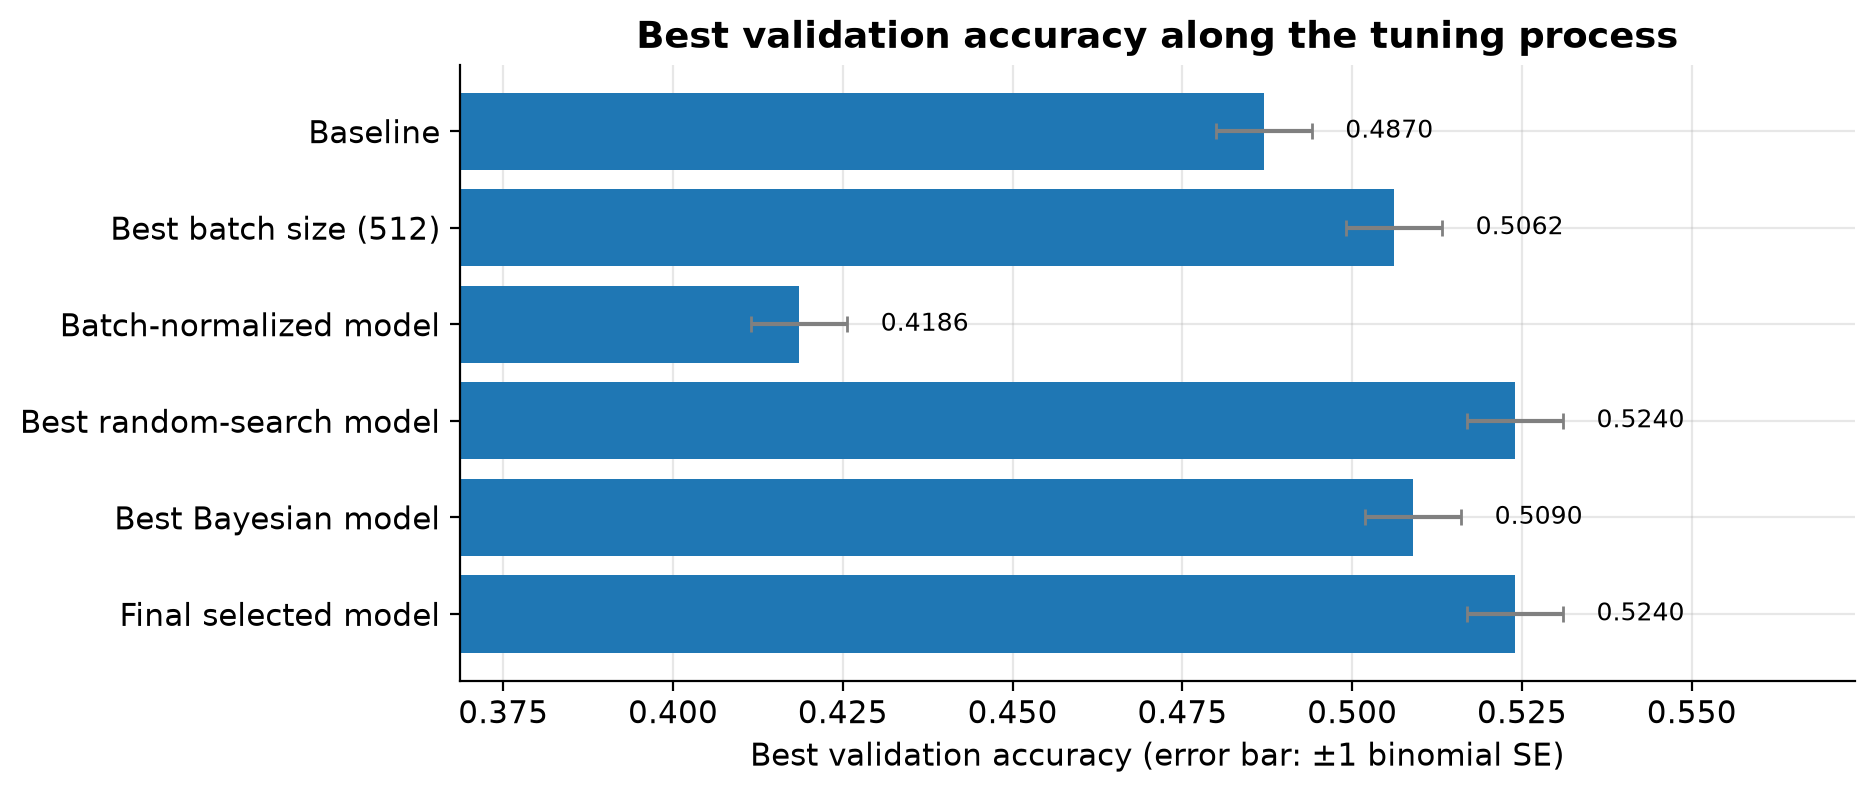

In [34]:
values = table2["Best validation accuracy"].astype(float)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(values.index[::-1], values[::-1], xerr=VAL_SE, color="C0", ecolor="grey", capsize=3)
ax.bar_label(bars, fmt="%.4f", padding=12, fontsize=9)
ax.set(
    title="Best validation accuracy along the tuning process",
    xlabel="Best validation accuracy (error bar: ±1 binomial SE)",
    xlim=(values.min() - 0.05, min(1.0, values.max() + 0.05)),
)
plt.show()

**Most important findings.** Tuning raised the best validation accuracy from **48.70 %** (baseline) to **52.40 %**, a gain of 3.7 points or about 5.2 standard errors, and the final model scored **52.01 %** on the test set. Of the controlled steps, batch size 512 contributed +1.9 points (2.7 standard errors) and cut training time by more than half (69 s to 30 s), while batch normalization on its own *lowered* validation accuracy by 8.8 points, most likely because it let the unregularized network memorise the training set (59-point train–validation gap). The best search configuration added a further +1.8 points over the batch-512 model. It combines batch normalization with dropout 0.4 and a lower learning rate of 0.0005, but it differs from the batch-512 model in five settings at once, so the gain cannot be assigned to any single one of them. Dropout was the most consistent factor across both searches: the three trials without dropout were the three worst of the 15 distinct search configurations. Under the same 8-trial budget, random search beat Bayesian optimization by 1.5 points (2.1 standard errors), and TPE spent one trial on a repeat. The 0.39-point validation-to-test gap is within noise, consistent with the selection generalizing. For this dense network on CIFAR-10, the decisive lever was controlling overfitting, not adding capacity or speeding up optimization.

## Final analysis and reflection

### Question 1

*How did batch size, batch normalization, and the searched hyperparameters affect (a) training stability and convergence and (b) validation performance and generalization?*

Two kinds of evidence are used below and kept separate. Steps 3 and 4 are **controlled**: one variable changes, so differences can be attributed to it. The 16 search trials change five hyperparameters at once, so patterns across them are **correlational**. Every number comes from a single seed per configuration, so differences under about one point (one standard error on 5,000 validation images is 0.71 points) are not reliable.

**(a) Training stability and convergence.**

*Batch size.* In the controlled comparison, batch size changed how fast the network converged per weight update far more than per epoch. Batch 128 reached 45 % validation accuracy in the fewest epochs (5, against 8 for batch 32 and 9 for batch 512). Batch 512 needed only 792 updates to get there against 11,256 for batch 32, and it reached its lowest validation loss (1.427) after about 1,850 updates, before batch 32 had even got below 1.60 (about 4,200 updates; Step 3, right-hand plot). Batch 32 also converged into overfitting earliest: its validation-loss minimum came at epoch 9, against 11 for batch 128 and 21 for batch 512. Epoch-level stability was essentially unaffected (val-acc noise 0.74–1.07 points for all three), so the larger per-step gradient noise of small batches did not appear as noisier validation curves.

*Batch normalization.* BN accelerated convergence on the training set dramatically. Training loss was 1.05 after five epochs against 1.58 without BN, and training accuracy reached 95.8 % against 61.5 % by epoch 30. But it made validation behaviour less stable: val-acc noise rose from 0.92 to 2.69 points, validation accuracy swung by up to about 11 points between epochs, and validation loss bottomed out at epoch 5 and then rose 187 %. BN made the optimization problem easier, and without any regularization, the easier problem the network solved was memorisation.

*Searched hyperparameters.* The searches suggest that dropout mattered most for stability, with the learning rate second. Of the six distinct dropout-0.4 trials, five had smooth validation curves; the exception (Bayesian trial 2) used the highest learning rate with a 2 × 512 network. Of the nine distinct trials with dropout 0 or 0.2, eight were flagged as noisy or overfitting; the only exception was Random trial 7, at the lowest learning rate (0.0001). The two lr-0.0001 trials were both smooth, and Bayesian trial 3 (batch 32, dropout 0.4) was still improving at the last epoch (best accuracy at epoch 28). Counting distinct trials, the instability flag was raised in 0 of 2 at learning rate 0.0001, 3 of 5 at 0.0005 (all three with dropout 0 or 0.2), and 3 of 4 at both 0.001 and 0.005. The one smooth lr-0.005 trial (Random trial 8) paired it with dropout 0.4 and a small network. Depth and width showed no consistent effect on convergence at this budget.

**(b) Validation performance and generalization.**

*Batch size.* Batch 512 generalized best in the controlled comparison: the highest best validation accuracy (50.62 %), the lowest best validation loss (1.427), and the smallest validation-loss rise after its minimum (4.2 %, against 11.9 % for batch 128 and 17.6 % for batch 32). This is the opposite of the small-batch regularization effect sometimes reported (Keskar et al., 2017). The likely reason is that, under a fixed 30-epoch budget and a fixed learning rate, batch 32 took 16 times as many updates and so reached the overfitting regime sooner. The design holds epochs fixed, so it cannot separate this from the effect of gradient noise.

*Batch normalization.* On its own, BN hurt generalization badly: best validation accuracy fell from 50.62 % to 41.86 % (about 12 standard errors) and the final train–validation gap grew from 12.6 to 59.3 points.

*Searched hyperparameters.* Generalization tracked dropout most closely. Five of the six dropout-0.4 trials ended below the 15-point gap flag, against final train–validation gaps of 47–63 points for the three no-dropout trials, which were also the three worst search results (40.8–43.8 %). The single best configuration (Random trial 5) combined BN with dropout 0.4 and a moderate learning rate (0.0005), and produced both the best validation accuracy (52.40 %) and the lowest validation loss (1.351) in the notebook. The runner-up (Random trial 6, 52.06 %) used the same learning rate with dropout 0.2 and overfit more.

*Limitations.* Every search trial used BN, so the search cannot say whether BN helps once dropout is present. The comparison that would answer it, the same dropout-0.4 network with and without BN, was not run. With one seed per configuration, seed-to-seed variation was not measured and may be comparable to some of the differences between search trials.

### Question 2

*How did random search and Bayesian optimization compare under the same trial budget, and why is the final selected configuration appropriate for this task?*

**Random search vs. Bayesian optimization.** With 8 trials each over the same 432-point space, random search found the better configuration: 52.40 % against TPE's 50.90 %, a difference of 1.5 points or about 2.1 standard errors. Random search also found the only two strong configurations (within one standard error of the best), reaching the first at trial 5. TPE never reached that level: its best-so-far value stayed at the 49.84 % of its first random start-up trial until trial 8. TPE was cheaper (about 7 minutes against about 10, 100,000 weight updates against 127,000), partly because it proposed a repeat of trial 1 at trial 4, which cost no training but also produced no new information. Its spread of scores was slightly narrower (standard deviation 3.31 vs. 4.02 points) and it had one fewer unstable trial, but its mean score was lower (47.6 % vs. 48.2 %). Neither search had failed trials. The three random start-up trials matter a great deal at this budget: they leave TPE only five model-guided proposals, built from three observations, and one of those (trial 5, no dropout) was the worst trial of either search. After that failure every TPE proposal used dropout. That is consistent with TPE learning from the failure, but it is weak evidence: if dropout were drawn at random, three proposals in a row with dropout above zero would occur about 30 % of the time ((2/3)³). These results cannot rank the two methods in general. Each method was run once, with one seed per configuration, and random search's best result depended on one fortunate draw (learning rate 0.0005 with dropout 0.4). A fair ranking would need repeated searches with different sampler seeds and a larger budget, where TPE's density model has enough data to be useful.

**Why the final configuration is appropriate.** The final model (4 × 256 hidden units, BN, dropout 0.4, learning rate 0.0005, batch size 128, 26 epochs) was chosen on validation evidence alone. It has the highest best validation accuracy of all 19 distinct runs and the lowest validation loss, and its one contender within a standard error (Random trial 6) is larger, overfits more and is noisier. Each setting is plausible for a dense network on flattened CIFAR-10. Because the search changed all five settings together, the reasons that follow are consistent with the evidence, not separately tested effects. On capacity, 4 × 256 (about 0.99 million parameters, fewer than the baseline's 1.74 million) has less capacity than the baseline yet scored best, while the 512-wide trials overfit more (31- and 41-point final gaps in Random trials 6 and 1, 28 points in Bayesian trial 2), although they also differ in learning rate or dropout. Dropout 0.4 directly counters the memorisation that dominated the BN-only and no-dropout runs: trial 5 ended its 30-epoch run below the 15-point gap flag, against final gaps of 47–63 points for the three no-dropout trials. Learning rate 0.0005 gave smooth curves in both trials that paired it with dropout 0.4 (Random 5 and Bayesian 1), while the same learning rate with dropout 0.2 or 0 was noisy or overfit (Random 6, Bayesian 5 and 6), so the learning rate works here together with strong dropout, not on its own. Batch size 128 keeps the cost moderate: 352 updates per epoch at about 2.5 s per epoch on a CPU.

The 0.39-point gap between validation (52.40 %) and test accuracy (52.01 %) is within the noise of the two estimates, which is consistent with the selection not having overfit the validation set.

**Limitations.** The model's validation accuracy falls from 52.4 % at epoch 26 to 47.7 % at epoch 30, so its best-epoch score is partly a favourable peak. The matching test score suggests the epoch-26 model is genuinely good, but a learning-rate schedule or early stopping on validation loss would make the epoch choice less fragile. Each configuration was trained with a single seed, so seed-to-seed variation is unknown, and the 30-epoch cap favours settings that converge quickly. Finally, the architecture has no convolutional structure; at this budget and without data augmentation, that kept every model here near 50 % accuracy.

**With more budget.** Train several seeds per configuration, use a larger search budget (30–50 trials) so TPE's model can be compared fairly, run the missing BN-with-and-without-dropout ablation, and add weight decay, a learning-rate schedule and data augmentation. The largest remaining gain would come from changing the model family to a convolutional network, the subject of the next assignment.

## References and acknowledgements

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). https://doi.org/10.1145/3292500.3330701

Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization. In *Advances in Neural Information Processing Systems 24* (pp. 2546–2554).

Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.

Chollet, F. (2021). *Deep learning with Python* (2nd ed.). Manning.

Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. In *Proceedings of the 32nd International Conference on Machine Learning* (pp. 448–456). PMLR.

Keskar, N. S., Mudigere, D., Nocedal, J., Smelyanskiy, M., & Tang, P. T. P. (2017). On large-batch training for deep learning: Generalization gap and sharp minima. In *International Conference on Learning Representations*.

Krizhevsky, A. (2009). *Learning multiple layers of features from tiny images* [Technical report]. University of Toronto.

**Data:** CIFAR-10, loaded with `keras.datasets.cifar10`. **Software:** TensorFlow and Keras (models and training), scikit-learn (stratified split, confusion matrix), Optuna (TPE sampler), NumPy, pandas, and Matplotlib.